# Retail Sales: data audit and exploratory analysis

## Objectives

We investigate the structure and quality of the retail data before building
forecasting models. We examine temporal coverage, relationships between tables,
missing values, duplicate keys, returns, and unusual prices.

We then explore sales patterns across stores, categories, and products,
including trends, seasonality, promotions, and changes in assortment.

We use these findings to define a forecasting task and a chronological
evaluation strategy with time-series cross-validation. We reserve a final
holdout period before exploring sales patterns or selecting models.

In [24]:
from pathlib import Path
import gc
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": COLORS["dark"],
        "text.color": COLORS["dark"],
        "grid.alpha": 0.25,
    },
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Source files and table structure

We first locate the source files and inspect their schemas using small samples.
We avoid loading every table into memory at once.

At this stage, we check file availability and column types. We do not interpret
missing sales records as zero demand, remove negative values, or combine online
and other sales until we establish what these records represent.

In [25]:
working_dir = Path.cwd().resolve()
project_candidates = [working_dir, *working_dir.parents]

PROJECT_ROOT = next(
    (
        path
        for path in project_candidates
        if (path / "data" / "raw" / "retail").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/raw/retail/. "
        "Start Jupyter inside the project directory."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "retail"

EXPECTED_FILES = [
    "sales.csv",
    "online.csv",
    "catalog.csv",
    "stores.csv",
    "price_history.csv",
    "discounts_history.csv",
    "markdowns.csv",
    "actual_matrix.csv",
]

missing_files = [
    name for name in EXPECTED_FILES
    if not (DATA_DIR / name).is_file()
]

if missing_files:
    raise FileNotFoundError(f"Missing source files: {missing_files}")

file_inventory = pd.DataFrame(
    {
        "file": name,
        "size_mb": (DATA_DIR / name).stat().st_size / 1_000_000,
    }
    for name in EXPECTED_FILES
)

display(file_inventory)

samples = {}

for name in EXPECTED_FILES:
    sample = pd.read_csv(DATA_DIR / name, nrows=5_000)

    sample = sample.drop(columns=["Unnamed: 0"], errors="ignore")
    samples[Path(name).stem] = sample

    print(f"\n{'=' * 60}\n{name} — sample only")
    display(sample.head(3))
    display(
        sample.dtypes.astype(str)
        .rename("sample_dtype")
        .to_frame()
    )

,file,size_mb
0,sales.csv,379.235
1,online.csv,56.840
2,catalog.csv,25.439
3,stores.csv,0.000
4,price_history.csv,29.280
5,discounts_history.csv,341.483
6,markdowns.csv,0.426
7,actual_matrix.csv,1.115



sales.csv — sample only


,date,item_id,quantity,price_base,sum_total,store_id
0,2023-08-04,293375605257,1.000,47.860,47.860,1
1,2023-08-04,a66fdf2c0ae7,3.000,49.600,148.800,1
2,2023-08-04,daa46ef49b7a,0.822,379.000,311.540,1


,sample_dtype
date,object
item_id,object
quantity,float64
price_base,float64
sum_total,float64
store_id,int64



online.csv — sample only


,date,item_id,quantity,price_base,sum_total,store_id
0,2023-08-04,4aa8dbe05246,3.000,12.400,37.210,1
1,2023-08-04,4e0fbcf99cf9,2.000,56.270,112.540,1
2,2023-08-04,2e008b673129,2.000,56.270,112.540,1


... (15 outputs left out)

,sample_dtype
date,object
item_id,object
normal_price,float64
price,float64
quantity,float64
store_id,int64



actual_matrix.csv — sample only


,item_id,date,store_id
0,c578da8e8841,2019-10-17,1
1,4dd2b686802c,2019-10-17,1
2,16ade2e3fca9,2019-10-17,1


,sample_dtype
item_id,object
date,object
store_id,int64


## 2. Sales data quality and temporal coverage

We load the complete sales table and check missing values, invalid dates,
non-finite numeric values, and repeated records.

We test whether a date–store–item combination uniquely identifies a row.
Repeated combinations may represent multiple sales records, so we do not
remove them automatically.

We also inspect date coverage for each store. A day without records does not
necessarily mean zero sales: it may indicate closure or missing data.

In [26]:
SALES_COLUMNS = [
    "date", "item_id", "quantity",
    "price_base", "sum_total", "store_id",
]

sales = pd.read_csv(
    DATA_DIR / "sales.csv",
    usecols=SALES_COLUMNS,
    dtype={
        "date": "string",
        "item_id": "string",
        "store_id": "Int64",
        "quantity": "float64",
        "price_base": "float64",
        "sum_total": "float64",
    },
)

raw_dates = sales["date"]
parsed_dates = pd.to_datetime(
    raw_dates, format="%Y-%m-%d", errors="coerce"
)

invalid_date_count = int(
    (raw_dates.notna() & parsed_dates.isna()).sum()
)
sales["date"] = parsed_dates

print(f"Rows: {len(sales):,}")
print(
    "Memory usage: "
    f"{sales.memory_usage(deep=True).sum() / 1_000_000:,.1f} MB"
)

missing_summary = pd.DataFrame({
    "missing_count": sales.isna().sum(),
    "missing_pct": sales.isna().mean().mul(100),
})
display(missing_summary)

numeric_columns = ["quantity", "price_base", "sum_total"]
numeric_checks = []

for column in numeric_columns:
    values = sales[column]
    numeric_checks.append({
        "column": column,
        "infinite_count": int(np.isinf(values).sum()),
        "negative_count": int(values.lt(0).sum()),
        "zero_count": int(values.eq(0).sum()),
    })

display(pd.DataFrame(numeric_checks).set_index("column"))
print(f"Non-missing dates that failed parsing: {invalid_date_count:,}")

key = ["date", "store_id", "item_id"]

duplicate_summary = pd.Series({
    "exact_duplicate_rows_beyond_first":
        int(sales.duplicated().sum()),
    "repeated_key_rows_beyond_first":
        int(sales.duplicated(key).sum()),
    "all_rows_in_repeated_key_groups":
        int(sales.duplicated(key, keep=False).sum()),
}, name="count")

display(duplicate_summary.to_frame())

Rows: 7,432,685
Memory usage: 758.1 MB


,missing_count,missing_pct
date,0,0.000
item_id,0,0.000
quantity,0,0.000
price_base,0,0.000
sum_total,0,0.000
store_id,0,0.000


,infinite_count,negative_count,zero_count
column,,,
quantity,0,1160,2438
price_base,0,67,8026
sum_total,0,1610,6593


Non-missing dates that failed parsing: 0


,count
exact_duplicate_rows_beyond_first,0
repeated_key_rows_beyond_first,0
all_rows_in_repeated_key_groups,0


### Initial data quality findings

We found no missing values, invalid dates, or infinite numeric values in
7,432,685 sales records. Both full rows and date–store–item combinations
are unique, so no additional aggregation is required at this level.

However, the table contains negative and zero quantities, prices, and amounts.
Negative amounts occur more frequently than negative quantities, suggesting
that a single explanation may not cover all these records. We retain them
until we inspect their sign combinations and possible business meanings.

These checks confirm structural consistency, but they do not establish
whether the recorded values are correct or whether every expected observation
is present.

,first_date,last_date,observed_days,calendar_days_in_store_span,missing_days_in_store_span,coverage_pct
store_id,,,,,,
1,2022-08-28,2024-09-26,761,761,0,100.000
2,2022-08-28,2024-09-26,761,761,0,100.000
3,2022-08-28,2024-09-26,760,761,1,99.869
4,2023-12-13,2024-09-26,289,289,0,100.000


Store 1: 0 missing dates within its span. First examples: []
Store 2: 0 missing dates within its span. First examples: []
Store 3: 1 missing dates within its span. First examples: ['2022-10-16']
Store 4: 0 missing dates within its span. First examples: []


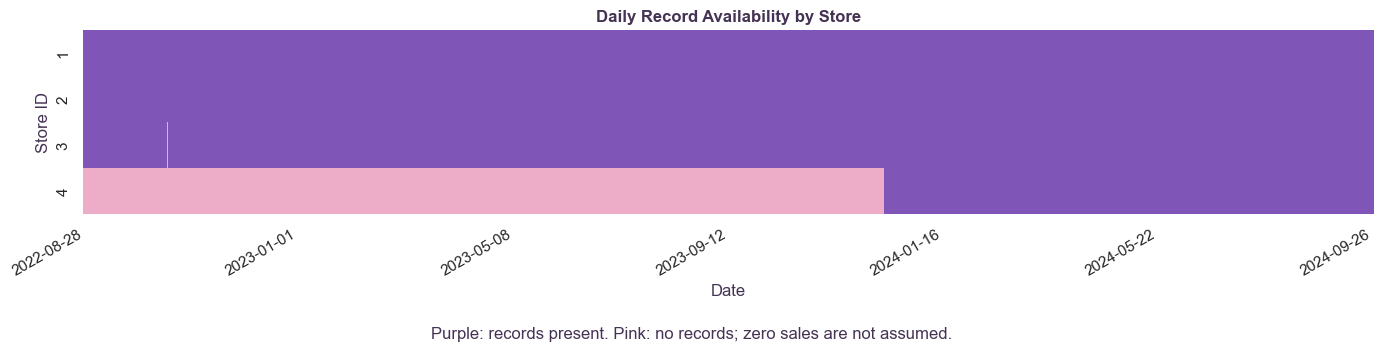

In [27]:
coverage_source = sales.dropna(subset=["date", "store_id"])

daily_record_counts = (
    coverage_source
    .groupby(["date", "store_id"], observed=True)
    .size()
    .rename("record_count")
    .unstack("store_id")
)

if daily_record_counts.empty:
    raise ValueError("No valid date–store records are available.")

full_calendar = pd.date_range(
    coverage_source["date"].min(),
    coverage_source["date"].max(),
    freq="D",
)

daily_record_counts = daily_record_counts.reindex(full_calendar)
daily_record_counts.index.name = "date"

coverage_rows = []
missing_dates_by_store = {}

for store_id in daily_record_counts.columns:
    observed_dates = daily_record_counts[store_id].dropna().index

    first_date = observed_dates.min()
    last_date = observed_dates.max()
    own_calendar = pd.date_range(first_date, last_date, freq="D")

    missing_dates = own_calendar.difference(observed_dates)
    missing_dates_by_store[store_id] = missing_dates

    coverage_rows.append({
        "store_id": store_id,
        "first_date": first_date,
        "last_date": last_date,
        "observed_days": len(observed_dates),
        "calendar_days_in_store_span": len(own_calendar),
        "missing_days_in_store_span": len(missing_dates),
        "coverage_pct": 100 * len(observed_dates) / len(own_calendar),
    })

store_coverage = (
    pd.DataFrame(coverage_rows)
    .set_index("store_id")
    .sort_index()
)

display(store_coverage)

for store_id, dates in missing_dates_by_store.items():
    examples = [date.strftime("%Y-%m-%d") for date in dates[:10]]
    print(
        f"Store {store_id}: {len(dates)} missing dates within its span. "
        f"First examples: {examples}"
    )

fig, ax = plt.subplots(figsize=(14, 3.5))

sns.heatmap(
    daily_record_counts.notna().T.astype(int),
    cmap=[COLORS["rose"], COLORS["purple"]],
    vmin=0,
    vmax=1,
    cbar=False,
    xticklabels=False,
    ax=ax,
)

tick_positions = np.unique(
    np.linspace(0, len(full_calendar) - 1, 7, dtype=int)
)

ax.set_xticks(tick_positions + 0.5)
ax.set_xticklabels(
    full_calendar[tick_positions].strftime("%Y-%m-%d"),
    rotation=30,
    ha="right",
)

ax.set_title("Daily Record Availability by Store")
ax.set_xlabel("Date")
ax.set_ylabel("Store ID")

fig.text(
    0.5, 0.01,
    "Purple: records present. Pink: no records; zero sales are not assumed.",
    ha="center",
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

### Temporal coverage findings

Stores 1 and 2 have records on all 761 days between 2022-08-28 and
2024-09-26. Store 3 has one day without records: 2022-10-16.
We retain this date as missing rather than assuming zero sales.

Store 4 first appears on 2023-12-13 and has records on every subsequent
day. The data alone do not establish whether this is its opening date
or the beginning of data collection.

Combining all stores may introduce a change caused by store coverage.
We therefore examine stores 1–3 as a fixed group and analyse store 4
separately. Store-level daily coverage does not establish completeness
at the item level.

## 3. Final holdout reservation

We reserve the last 28 calendar days, from 2024-08-30 to 2024-09-26,
for final evaluation. This four-week horizon contains each weekday
exactly four times.

We use the preceding period for exploratory analysis and model development.
Model selection uses chronological cross-validation with 28-day validation
windows. We fit preprocessing steps separately within each training fold.

We do not use holdout sales values to select products, features,
transformations, or models. Final evaluation represents one four-week
period, so cross-validation is needed to assess performance at other origins.

In [28]:
FORECAST_HORIZON = 28
TEST_END = pd.Timestamp("2024-09-26")
TEST_START = TEST_END - pd.Timedelta(days=FORECAST_HORIZON - 1)

assert sales["date"].notna().all()
assert sales["date"].max() == TEST_END

sales_dev = sales.loc[sales["date"] < TEST_START].copy()

split_summary = pd.DataFrame([
    {
        "partition": "development",
        "start": sales_dev["date"].min(),
        "end": TEST_START - pd.Timedelta(days=1),
        "calendar_days": (
            TEST_START - sales_dev["date"].min()
        ).days,
    },
    {
        "partition": "final_test",
        "start": TEST_START,
        "end": TEST_END,
        "calendar_days": FORECAST_HORIZON,
    },
])

assert sales_dev["date"].max() < TEST_START
display(split_summary)

del sales, coverage_source
gc.collect()

,partition,start,end,calendar_days
0,development,2022-08-28,2024-08-29,733
1,final_test,2024-08-30,2024-09-26,28


40722

## 4. Negative and zero values

We examine combinations of quantity, price, and amount signs to distinguish
different types of unusual records. These patterns may be consistent with
returns, adjustments, free items, or data issues, but they do not establish
the business meaning on their own.

We measure both the frequency and monetary magnitude of these records.
A small number of unusual rows may still have a substantial impact.

All checks in this section use the development period. We retain the
original values until we have enough evidence to define processing rules.

In [29]:
def value_sign(series):
    return np.select(
        [series.lt(0), series.eq(0), series.gt(0)],
        ["negative", "zero", "positive"],
        default="missing",
    )


sign_summary = (
    sales_dev
    .groupby(
        [
            value_sign(sales_dev["quantity"]),
            value_sign(sales_dev["price_base"]),
            value_sign(sales_dev["sum_total"]),
        ],
        sort=True,
    )
    .agg(
        rows=("item_id", "size"),
        net_amount=("sum_total", "sum"),
        absolute_amount=("sum_total", lambda s: s.abs().sum()),
    )
)

sign_summary.index.names = [
    "quantity_sign", "price_sign", "amount_sign"
]

sign_summary["rows_pct"] = (
    100 * sign_summary["rows"] / len(sales_dev)
)

total_absolute_amount = sales_dev["sum_total"].abs().sum()

sign_summary["absolute_amount_pct"] = (
    100 * sign_summary["absolute_amount"] / total_absolute_amount
    if total_absolute_amount > 0
    else np.nan
)

sign_summary = sign_summary.sort_values("rows", ascending=False)

display(sign_summary)

rows        net_amount  \
quantity_sign price_sign amount_sign                              
positive      positive   positive     7042182 5,351,867,776.150   
              zero       zero            5480             0.000   
negative      positive   negative        1087      -784,292.430   
zero          zero       zero             995             0.000   
                         positive         887         7,997.340   
                         negative         458       -74,378.840   
negative      negative   positive          41         9,059.110   
positive      zero       positive          27             0.440   
              negative   negative          25        -8,024.080   
negative      zero       zero               8             0.000   

                                       absolute_amount  rows_pct  \
quantity_sign price_sign amount_sign                               
positive      positive   positive    5,351,867,776.150    99.872   
              zero       zero                    0.000     0.078   
negative      positive   negative          784,292.430     0.015   
zero          zero       zero                    0.000     0.014   
                         positive            7,997.340     0.013   
                         negative           74,378.840     0.006   
negative      negative   positive            9,059.110     0.001   
positive      zero       positive                0.440     0.000   
              negative   negative            8,024.080     0.000   
negative      zero       zero                    0.000     0.000   

                                      absolute_amount_pct  
quantity_sign price_sign amount_sign                       
positive      positive   positive                  99.983  
              zero       zero                       0.000  
negative      positive   negative                   0.015  
zero          zero       zero                       0.000  
                         positive                   0.000  
                         negative                   0.001  
negative      negative   positive                   0.000  
positive      zero       positive                   0.000  
              negative   negative                   0.000  
negative      zero       zero                       0.000

In [30]:
unusual_masks = {
    "Negative quantity": sales_dev["quantity"].lt(0),
    "Negative price": sales_dev["price_base"].lt(0),
    "Negative amount": sales_dev["sum_total"].lt(0),
    "Zero quantity with non-zero amount": (
        sales_dev["quantity"].eq(0)
        & sales_dev["sum_total"].ne(0)
    ),
    "Positive quantity with zero amount": (
        sales_dev["quantity"].gt(0)
        & sales_dev["sum_total"].eq(0)
    ),
    "Zero price with non-zero amount": (
        sales_dev["price_base"].eq(0)
        & sales_dev["sum_total"].ne(0)
    ),
}

example_columns = [
    "date", "store_id", "item_id",
    "quantity", "price_base", "sum_total",
]

for label, mask in unusual_masks.items():
    print(f"\n{label}: {int(mask.sum()):,} rows")

    example_indices = (
        sales_dev.loc[mask, "sum_total"]
        .abs()
        .nlargest(5)
        .index
    )

    display(sales_dev.loc[example_indices, example_columns])


Negative quantity: 1,136 rows


,date,store_id,item_id,quantity,price_base,sum_total
5197845,2024-02-29,3,8250099a8aff,-292.000,69.900,"-20,410.800"
971183,2024-02-28,1,bbac937996b7,-8.000,"2,500.000","-20,000.000"
5185423,2024-02-18,3,76dc491fa971,-1.000,"14,990.000","-14,990.000"
5161908,2024-01-26,3,b7c20387fcdb,-91.000,139.010,"-12,649.750"
6586717,2024-04-29,4,ff2bd46579d6,-182.000,62.960,"-11,459.020"



Negative price: 66 rows


,date,store_id,item_id,quantity,price_base,sum_total
3416504,2023-06-16,1,71ecf5eaeb3f,5.000,-946.120,"-4,730.600"
81056,2023-08-27,1,9fb64cd80a25,-0.216,"-4,494.950",970.910
6796098,2024-06-05,4,7a675a977b18,-0.092,"-9,483.800",872.510
3953938,2024-02-13,2,7a675a977b18,-0.265,"-2,375.660",629.550
3328711,2023-05-28,1,253ab68ae78c,1.000,-590.100,-590.100



Negative amount: 1,570 rows


,date,store_id,item_id,quantity,price_base,sum_total
5197845,2024-02-29,3,8250099a8aff,-292.000,69.900,"-20,410.800"
971183,2024-02-28,1,bbac937996b7,-8.000,"2,500.000","-20,000.000"
5185423,2024-02-18,3,76dc491fa971,-1.000,"14,990.000","-14,990.000"
5161908,2024-01-26,3,b7c20387fcdb,-91.000,139.010,"-12,649.750"
6586717,2024-04-29,4,ff2bd46579d6,-182.000,62.960,"-11,459.020"


... (2 outputs left out)


Positive quantity with zero amount: 5,480 rows


,date,store_id,item_id,quantity,price_base,sum_total
2301,2023-08-04,1,779193b74e9b,1.000,0.000,0.000
5686,2023-08-07,1,95833d99e8e4,1.000,0.000,0.000
6905,2023-08-07,1,d23debae34e6,1.000,0.000,0.000
9322,2023-08-07,1,245abe1b167b,1.000,0.000,0.000
9393,2023-08-07,1,d7202fe81b76,1.000,0.000,0.000



Zero price with non-zero amount: 1,372 rows


,date,store_id,item_id,quantity,price_base,sum_total
2162333,2022-09-22,1,7012f91280e8,0.000,0.000,"-2,788.000"
3109945,2023-04-13,1,f247f860e0ad,0.000,0.000,"1,399.000"
2186735,2022-09-27,1,7012f91280e8,0.000,0.000,"-1,394.000"
637273,2023-12-22,1,0ba1a8608e45,0.000,0.000,"-1,297.000"
675184,2023-12-29,1,0ba1a8608e45,0.000,0.000,"-1,297.000"


### Findings on unusual values

Positive quantity, price, and amount combinations account for 99.872%
of development records and 99.983% of the total absolute recorded amount.

We identified 1,087 records with negative quantities, positive prices,
and negative amounts. This pattern is consistent with possible returns,
although the available fields do not confirm their meaning.

Other patterns require separate consideration: 1,345 records have zero
quantity but non-zero amounts, 5,480 have positive quantity but zero amounts,
and 66 have negative prices.

Their aggregate monetary contribution is small, but their impact may be
concentrated in individual products or dates. We retain the original values
and avoid treating all unusual records as errors.

## 5. Quantity–Price–Amount Consistency

We compare the recorded amount with quantity multiplied by base price.
We examine ordinary positive records separately from other sign combinations.

A discrepancy does not necessarily indicate an error: the base price may
differ from the effective selling price, and aggregated records may include
rounding or adjustments. We use this check to identify patterns that need
further investigation.

In [31]:
expected_amount = sales_dev["quantity"] * sales_dev["price_base"]
absolute_gap = (sales_dev["sum_total"] - expected_amount).abs()

ordinary_mask = (
    sales_dev["quantity"].gt(0)
    & sales_dev["price_base"].gt(0)
    & sales_dev["sum_total"].gt(0)
)

amount_scale = pd.concat(
    [sales_dev["sum_total"].abs(), expected_amount.abs()],
    axis=1,
).max(axis=1)

relative_gap = absolute_gap.div(amount_scale.where(amount_scale.gt(0)))

consistency_rows = []

for label, mask in {
    "all_records": pd.Series(True, index=sales_dev.index),
    "positive_quantity_price_amount": ordinary_mask,
    "other_sign_combinations": ~ordinary_mask,
}.items():
    gaps = absolute_gap.loc[mask]
    rel_gaps = relative_gap.loc[mask].dropna()

    consistency_rows.append({
        "group": label,
        "rows": int(mask.sum()),
        "within_0.01_pct": 100 * gaps.le(0.01 + 1e-9).mean(),
        "within_0.10_pct": 100 * gaps.le(0.10 + 1e-9).mean(),
        "median_absolute_gap": gaps.median(),
        "p99_absolute_gap": gaps.quantile(0.99),
        "relative_gap_above_1pct_pct": (
            100 * rel_gaps.gt(0.01).mean()
        ),
    })

display(pd.DataFrame(consistency_rows).set_index("group"))

largest_gap_indices = (
    absolute_gap.loc[ordinary_mask].nlargest(10).index
)

gap_examples = sales_dev.loc[
    largest_gap_indices,
    ["date", "store_id", "item_id",
     "quantity", "price_base", "sum_total"],
].copy()

gap_examples["quantity_x_price"] = expected_amount.loc[largest_gap_indices]
gap_examples["absolute_gap"] = absolute_gap.loc[largest_gap_indices]
gap_examples["relative_gap_pct"] = (
    100 * relative_gap.loc[largest_gap_indices]
)

display(gap_examples)

,rows,within_0.01_pct,within_0.10_pct,median_absolute_gap,p99_absolute_gap,relative_gap_above_1pct_pct
group,,,,,,
all_records,7051190,87.754,98.354,0.000,0.150,0.048
positive_quantity_price_amount,7042182,87.758,98.370,0.000,0.150,0.028
other_sign_combinations,9008,84.913,85.535,0.000,299.951,54.416


,date,store_id,item_id,quantity,price_base,sum_total,quantity_x_price,absolute_gap,relative_gap_pct
679474,2023-12-30,1,b0d24502fb66,"4,447.000",7.910,"35,155.010","35,175.770",20.760,0.059
2823760,2023-02-12,1,6d284b4e9982,"3,548.000",44.600,"158,225.400","158,240.800",15.400,0.010
2812615,2023-02-10,1,6d284b4e9982,"4,243.000",44.970,"190,822.450","190,807.710",14.740,0.008
6615746,2024-05-04,4,b0d24502fb66,"2,950.000",7.890,"23,288.260","23,275.500",12.760,0.055
6643692,2024-05-09,4,b0d24502fb66,"2,630.000",7.900,"20,765.010","20,777.000",11.990,0.058
5944476,2023-12-30,4,b0d24502fb66,"4,464.000",7.910,"35,321.870","35,310.240",11.630,0.033
6293598,2024-03-07,4,b0d24502fb66,"2,892.000",7.910,"22,864.140","22,875.720",11.580,0.051
947854,2024-02-23,1,b0d24502fb66,"2,501.000",7.910,"19,794.060","19,782.910",11.150,0.056
1010267,2024-03-07,1,b0d24502fb66,"2,886.000",7.920,"22,868.200","22,857.120",11.080,0.048
2358041,2022-11-04,1,b0d24502fb66,"2,175.000",6.930,"15,083.460","15,072.750",10.710,0.071


### Quantity–price–amount consistency findings

Among records with positive quantity, price, and amount, 98.370% have
an absolute discrepancy no greater than 0.10. The 99th percentile of
the absolute discrepancy is 0.150, and only 0.028% have a relative
discrepancy above 1%.

The largest absolute discrepancies shown occur on high-quantity records
and remain small relative to their amounts. This is consistent with
possible price rounding, but does not establish its cause.

Other sign combinations behave differently: 54.416% of records with
a defined relative discrepancy exceed 1%. We therefore retain these
records for separate interpretation and preserve the original sum_total
rather than reconstructing it from quantity and price_base.

## 6. Reference tables and join integrity

We check whether item and store identifiers are unique in the reference
tables and whether development sales identifiers are covered.

We also examine missing product attributes for items appearing in
development sales. We validate reference keys before joining tables
to avoid multiplying sales records.

The catalog is a static snapshot. Without historical versions, we cannot
assume that every attribute was available at each forecasting origin.

In [32]:
catalog = pd.read_csv(
    DATA_DIR / "catalog.csv",
    dtype={"item_id": "string"},
).drop(columns=["Unnamed: 0"], errors="ignore")

stores = pd.read_csv(
    DATA_DIR / "stores.csv",
    dtype={"store_id": "Int64"},
).drop(columns=["Unnamed: 0"], errors="ignore")

reference_checks = pd.DataFrame([
    {
        "table": "catalog",
        "rows": len(catalog),
        "missing_keys": int(catalog["item_id"].isna().sum()),
        "duplicate_keys_beyond_first": int(
            catalog.duplicated("item_id").sum()
        ),
    },
    {
        "table": "stores",
        "rows": len(stores),
        "missing_keys": int(stores["store_id"].isna().sum()),
        "duplicate_keys_beyond_first": int(
            stores.duplicated("store_id").sum()
        ),
    },
])

display(reference_checks)

unknown_item_mask = ~sales_dev["item_id"].isin(catalog["item_id"])
unknown_store_mask = ~sales_dev["store_id"].isin(stores["store_id"])

join_coverage = pd.DataFrame([
    {
        "reference": "catalog",
        "unmatched_sales_rows": int(unknown_item_mask.sum()),
        "unmatched_sales_rows_pct": 100 * unknown_item_mask.mean(),
        "unmatched_unique_ids": sales_dev.loc[
            unknown_item_mask, "item_id"
        ].nunique(),
    },
    {
        "reference": "stores",
        "unmatched_sales_rows": int(unknown_store_mask.sum()),
        "unmatched_sales_rows_pct": 100 * unknown_store_mask.mean(),
        "unmatched_unique_ids": sales_dev.loc[
            unknown_store_mask, "store_id"
        ].nunique(),
    },
])

display(join_coverage)
display(stores)

catalog_dev = catalog.loc[
    catalog["item_id"].isin(sales_dev["item_id"].unique())
].copy()

attribute_missingness = pd.DataFrame({
    "missing_count": catalog_dev.isna().sum(),
    "missing_pct": catalog_dev.isna().mean().mul(100),
}).sort_values("missing_pct", ascending=False)

print(f"Catalog rows for development items: {len(catalog_dev):,}")
display(attribute_missingness)

if (
    reference_checks["missing_keys"].gt(0).any()
    or reference_checks["duplicate_keys_beyond_first"].gt(0).any()
):
    print("Reference keys require investigation before joining.")
else:
    print("Reference keys are valid for many-to-one joins.")

,table,rows,missing_keys,duplicate_keys_beyond_first
0,catalog,219810,0,0
1,stores,4,0,0


,reference,unmatched_sales_rows,unmatched_sales_rows_pct,unmatched_unique_ids
0,catalog,19068,0.270,616
1,stores,0,0.000,0


,store_id,division,format,city,area
0,4,Div1,MaxiEuro,City3,1887
1,3,Div2,Format-7 express,City2,109
2,2,Div2,Format-6,City1,210
3,1,Div1,Format-1,City1,1500


Catalog rows for development items: 27,143


,missing_count,missing_pct
fatness,26061,96.014
weight_volume,7077,26.073
weight_netto,4043,14.895
item_type,3777,13.915
subclass_name,0,0.000
class_name,0,0.000
dept_name,0,0.000
item_id,0,0.000


Reference keys are valid for many-to-one joins.


### Reference table findings

Both reference tables have unique, non-missing identifiers, allowing
validated many-to-one joins. All development store identifiers are covered.

However, 616 development item identifiers are absent from the catalog,
affecting 19,068 sales records (0.270%). We retain these records and assign
an explicit unknown category rather than dropping their sales.

The catalog covers 27,143 development items. Their category names are complete,
while product attributes have substantial missingness. Fatness is missing
for 96.014% of these items and may not apply to many product categories.
We do not interpret missing product attributes as zeros.

## 7. Daily sales patterns by store

We aggregate the original recorded amounts by date and store, retaining
negative adjustments. We keep dates without records as missing.

We compare daily amounts and trailing seven-day averages. Each store uses
its own vertical scale so that patterns remain visible despite differences
in sales magnitude.

We also compare all observed stores with the fixed group of stores 1–3.
The fixed-group total is missing whenever any member has no records.
Amounts are shown in source monetary units because the currency has not
yet been verified.

,observed_days,net_recorded_amount,mean_daily_amount,median_daily_amount,p10_daily_amount,p90_daily_amount,nonpositive_observed_days
store_id,,,,,,,
1,733,"2,983,230,215.280","4,069,891.153","3,788,745.390","3,167,988.872","5,284,150.304",0
2,733,"471,966,275.460","643,883.050","629,132.020","498,450.870","782,772.194",0
3,732,"587,095,764.260","802,043.394","853,866.450","454,918.961","1,071,305.350",0
4,261,"1,308,725,882.690","5,014,275.413","4,610,003.530","3,632,695.140","6,646,439.060",0


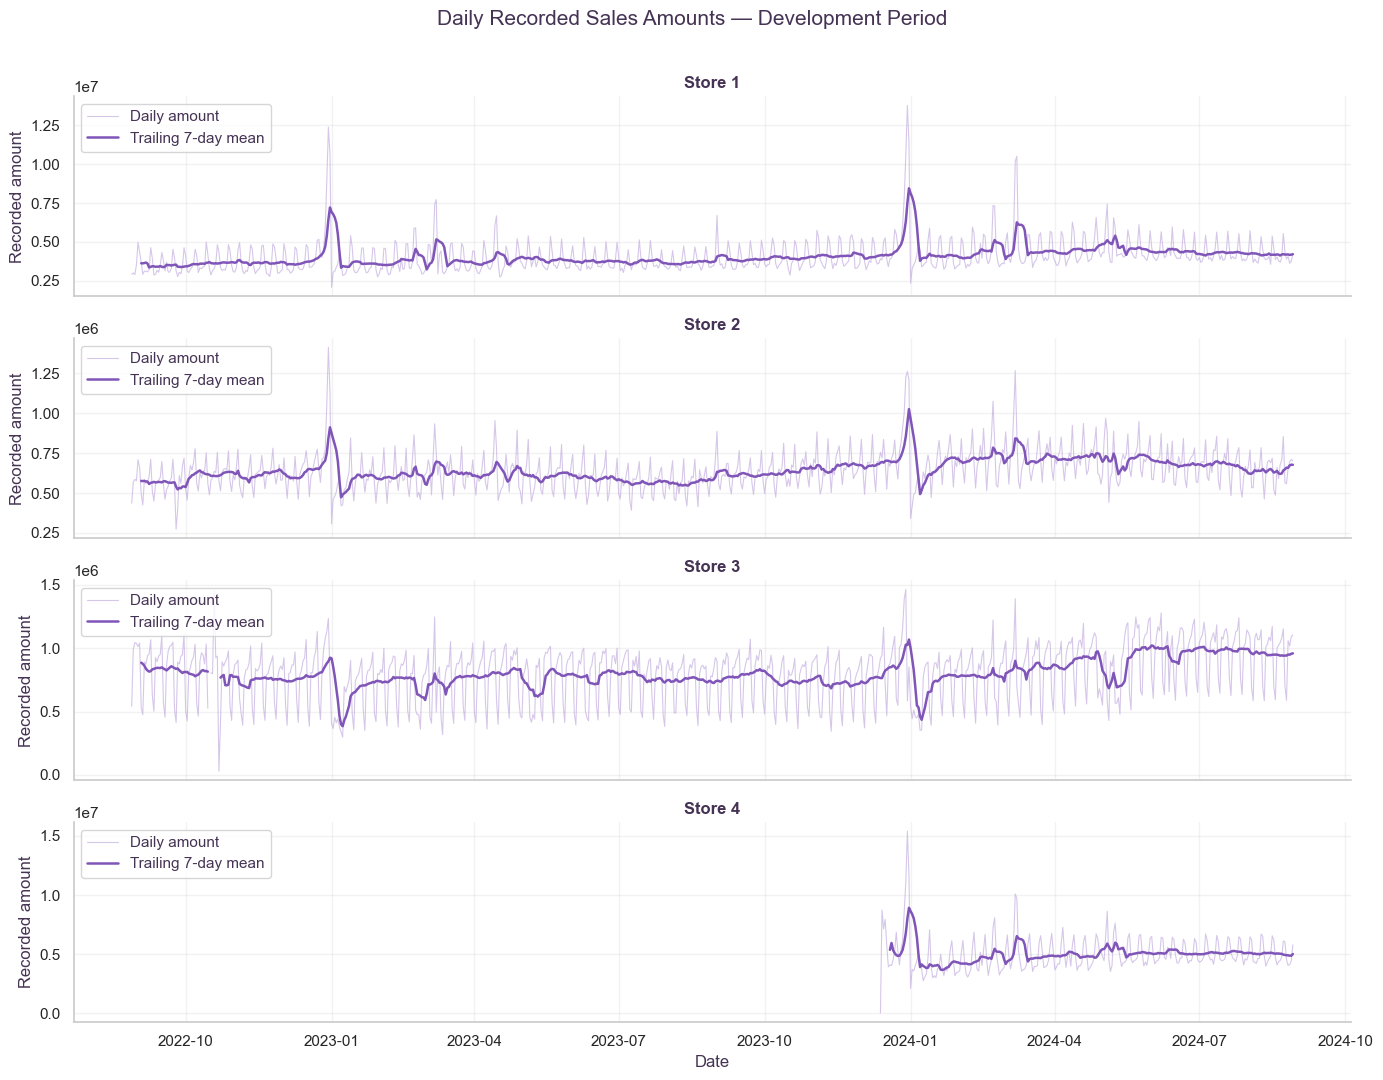

In [33]:
daily_amount = (
    sales_dev
    .groupby(["date", "store_id"], observed=True)["sum_total"]
    .sum(min_count=1)
    .unstack("store_id")
    .sort_index()
)

dev_calendar = pd.date_range(
    sales_dev["date"].min(),
    TEST_START - pd.Timedelta(days=1),
    freq="D",
)

daily_amount = daily_amount.reindex(dev_calendar)
daily_amount.index.name = "date"

store_summary = pd.DataFrame({
    "observed_days": daily_amount.count(),
    "net_recorded_amount": daily_amount.sum(min_count=1),
    "mean_daily_amount": daily_amount.mean(),
    "median_daily_amount": daily_amount.median(),
    "p10_daily_amount": daily_amount.quantile(0.10),
    "p90_daily_amount": daily_amount.quantile(0.90),
    "nonpositive_observed_days": daily_amount.le(0).sum(),
})

store_summary.index.name = "store_id"
display(store_summary)

rolling_amount = daily_amount.rolling(
    window=7, min_periods=7
).mean()

fig, axes = plt.subplots(
    len(daily_amount.columns), 1,
    figsize=(14, 11),
    sharex=True,
)

for ax, store_id in zip(axes, daily_amount.columns):
    ax.plot(
        daily_amount.index,
        daily_amount[store_id],
        color=COLORS["lavender"],
        alpha=0.55,
        linewidth=0.8,
        label="Daily amount",
    )
    ax.plot(
        rolling_amount.index,
        rolling_amount[store_id],
        color=COLORS["purple"],
        linewidth=1.8,
        label="Trailing 7-day mean",
    )
    ax.set_title(f"Store {store_id}")
    ax.set_ylabel("Recorded amount")
    ax.legend(loc="upper left")

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Daily Recorded Sales Amounts — Development Period",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

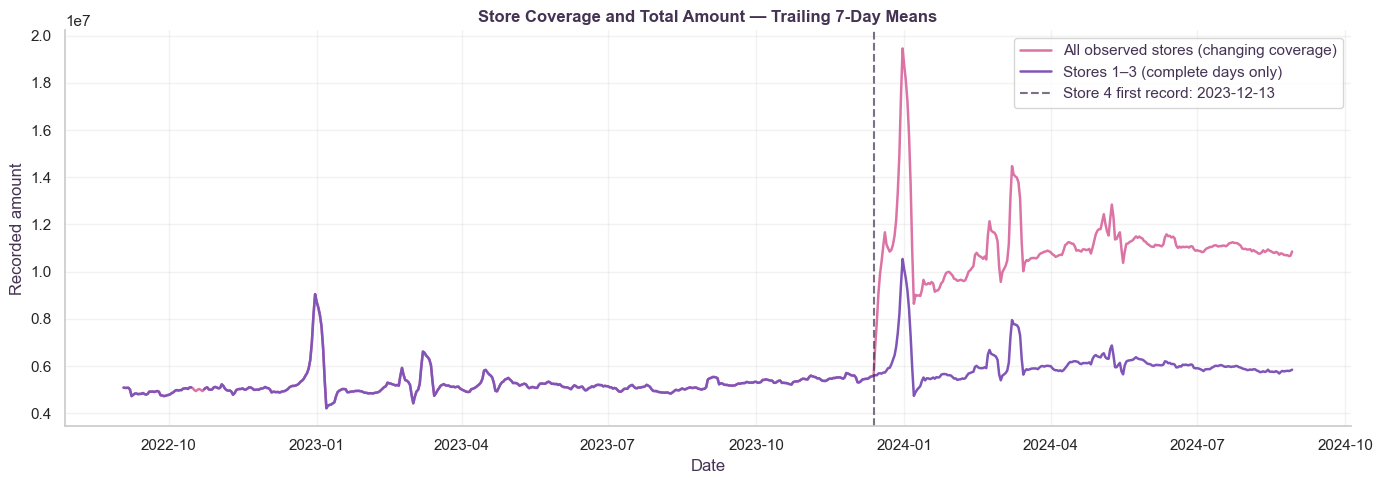

In [34]:
fixed_store_ids = [1, 2, 3]

fixed_group_amount = daily_amount[fixed_store_ids].sum(
    axis=1,
    min_count=len(fixed_store_ids),
)

all_observed_amount = daily_amount.sum(axis=1, min_count=1)

comparison = pd.DataFrame({
    "All observed stores (changing coverage)": all_observed_amount,
    "Stores 1–3 (complete days only)": fixed_group_amount,
})

comparison_rolling = comparison.rolling(
    window=7, min_periods=7
).mean()

fig, ax = plt.subplots(figsize=(14, 5))

for column, color in zip(
    comparison_rolling.columns,
    [COLORS["pink"], COLORS["purple"]],
):
    ax.plot(
        comparison_rolling.index,
        comparison_rolling[column],
        label=column,
        color=color,
        linewidth=1.8,
    )

store4_first_date = daily_amount[4].first_valid_index()
ax.axvline(
    store4_first_date,
    color=COLORS["dark"],
    linestyle="--",
    alpha=0.7,
    label=f"Store 4 first record: {store4_first_date:%Y-%m-%d}",
)

ax.set_title("Store Coverage and Total Amount — Trailing 7-Day Means")
ax.set_xlabel("Date")
ax.set_ylabel("Recorded amount")
ax.legend()
plt.tight_layout()
plt.show()

### Initial temporal patterns

Stores differ substantially in sales magnitude. However, their full-period
averages cover different date ranges, so we need a common observation window
for a fairer comparison.

The daily curves show recurring short-term fluctuations that suggest
weekday effects. Pronounced peaks appear near the ends of 2022 and 2023;
holiday demand is a possible explanation that requires further investigation.

The first appearance of store 4 substantially increases the combined amount.
The fixed group of stores 1–3 does not show an equivalent sustained increase,
so changing store coverage explains a substantial part of the aggregate shift.

We also observe sharp troughs, particularly in store 3. We retain these
observations until we examine their dates and underlying records.

## 8. Common-period comparison and weekday profiles

We compare stores over their shared development period, starting on
2023-12-13. We use dates with records for every store and report the
number of observations.

We then examine median daily amounts by weekday. We express each weekday
median relative to the store's overall daily median to compare profile
shapes across stores of different sizes.

These profiles are descriptive. They do not isolate weekday effects from
holidays, promotions, trends, or changes in assortment.

In [35]:
common_start = max(
    daily_amount[column].first_valid_index()
    for column in daily_amount.columns
)

common_daily = (
    daily_amount.loc[common_start:]
    .dropna(how="any")
    .copy()
)

common_summary = pd.DataFrame({
    "observed_days": common_daily.count(),
    "mean_daily_amount": common_daily.mean(),
    "median_daily_amount": common_daily.median(),
    "p10_daily_amount": common_daily.quantile(0.10),
    "p90_daily_amount": common_daily.quantile(0.90),
})

common_summary.index.name = "store_id"

print(
    f"Common period: {common_daily.index.min():%Y-%m-%d} "
    f"to {common_daily.index.max():%Y-%m-%d}"
)
display(common_summary)

Common period: 2023-12-13 to 2024-08-29


,observed_days,mean_daily_amount,median_daily_amount,p10_daily_amount,p90_daily_amount
store_id,,,,,
1,261,"4,496,531.490","4,063,603.120","3,595,501.550","5,682,648.070"
2,261,"699,540.886","694,763.390","549,590.440","853,966.430"
3,261,"878,899.920","935,918.920","540,448.350","1,145,934.120"
4,261,"5,014,275.413","4,610,003.530","3,632,695.140","6,646,439.060"


Median daily amounts by weekday:


store_id,1,2,3,4
Monday,"3,787,510.550","675,487.440","930,582.610","3,924,976.330"
Tuesday,"3,794,967.570","693,837.500","990,090.180","4,227,550.470"
Wednesday,"3,917,450.180","719,010.970","1,029,629.290","4,399,906.870"
Thursday,"4,222,467.195","742,791.965","1,053,443.320","4,646,563.650"
Friday,"5,635,813.450","842,341.450","1,090,241.660","6,265,219.990"
Saturday,"4,972,997.090","646,157.300","663,119.090","6,505,029.270"
Sunday,"3,977,505.930","555,349.270","542,019.940","4,767,406.490"


Observed days per weekday:


store_id,1,2,3,4
Monday,37,37,37,37
Tuesday,37,37,37,37
Wednesday,38,38,38,38
Thursday,38,38,38,38
Friday,37,37,37,37
Saturday,37,37,37,37
Sunday,37,37,37,37


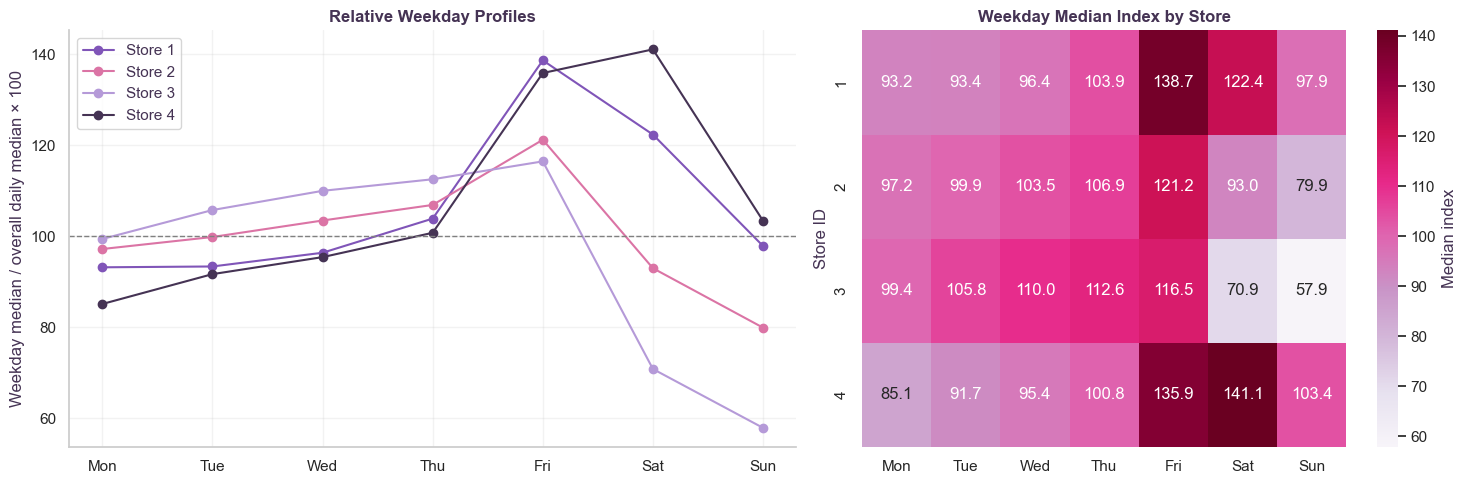

In [36]:
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

weekday_medians = (
    common_daily
    .groupby(common_daily.index.dayofweek)
    .median()
    .reindex(range(7))
)

weekday_counts = (
    common_daily
    .groupby(common_daily.index.dayofweek)
    .count()
    .reindex(range(7))
)

weekday_index = (
    weekday_medians
    .div(common_daily.median(), axis="columns")
    .mul(100)
)

weekday_medians.index = weekday_names
weekday_counts.index = weekday_names
weekday_index.index = weekday_names

print("Median daily amounts by weekday:")
display(weekday_medians)

print("Observed days per weekday:")
display(weekday_counts)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5),
    gridspec_kw={"width_ratios": [1.2, 1]},
)

store_colors = [
    COLORS["purple"], COLORS["pink"],
    COLORS["lavender"], COLORS["dark"],
]

for store_id, color in zip(weekday_index.columns, store_colors):
    axes[0].plot(
        range(7),
        weekday_index[store_id],
        marker="o",
        color=color,
        label=f"Store {store_id}",
    )

axes[0].axhline(100, color="grey", linestyle="--", linewidth=1)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(
    [name[:3] for name in weekday_names]
)
axes[0].set_title("Relative Weekday Profiles")
axes[0].set_ylabel("Weekday median / overall daily median × 100")
axes[0].legend()

sns.heatmap(
    weekday_index.T,
    annot=True,
    fmt=".1f",
    cmap="PuRd",
    center=100,
    ax=axes[1],
    cbar_kws={"label": "Median index"},
)

axes[1].set_title("Weekday Median Index by Store")
axes[1].set_xlabel("")
axes[1].set_ylabel("Store ID")
axes[1].set_xticklabels(
    [name[:3] for name in weekday_names],
    rotation=0,
)

plt.tight_layout()
plt.show()

### Common-period and weekday findings

Over the same 261-day period, store 4 has the highest mean daily recorded
amount, followed by stores 1, 3, and 2.

Stores 1–3 have their highest weekday median on Friday, whereas store 4
peaks on Saturday. Store 3 shows a particularly strong weekend decline:
its Sunday median is approximately half its Friday median.

These differences suggest that a shared weekday effect may be insufficient.
Store-specific seasonal models or store–weekday interactions are worth
testing. The profiles remain descriptive and do not establish the causes
of these differences.

## 9. Monthly Patterns, Autocorrelation, and Stationarity

We compare monthly mean daily amounts, using only months with a complete
calendar of observations for each store. This avoids comparing partial-month
totals with full months. Missing months remain missing.

We examine ACF and PACF on daily series and compare stationarity diagnostics
for the original series, first differences, and seven-day differences.

For store 3, we use the continuous segment after its missing date.
We do not compress time by removing an internal missing day.

ADF tests the null hypothesis of a unit root, while KPSS tests level
stationarity. We interpret these tests together with the plots. Neither
test alone establishes that a forecasting model is appropriate.

store_id,1,2,3,4
date,,,,
2023-09-01,"3,955,583.381","620,579.982","790,810.394",NaN
2023-10-01,"3,942,432.798","631,182.457","732,027.170",NaN
2023-11-01,"4,094,851.646","666,108.766","730,260.313",NaN
2023-12-01,"5,228,005.107","764,499.883","853,687.096",NaN
2024-01-01,"3,960,183.264","633,023.926","687,667.211","3,941,978.735"
2024-02-01,"4,370,349.137","722,444.769","788,738.807","4,600,576.492"
2024-03-01,"4,795,418.834","736,248.872","834,070.695","5,174,606.342"
2024-04-01,"4,466,170.176","720,221.816","897,794.733","4,927,049.660"
2024-05-01,"4,663,937.929","714,088.849","893,833.772","5,219,151.126"


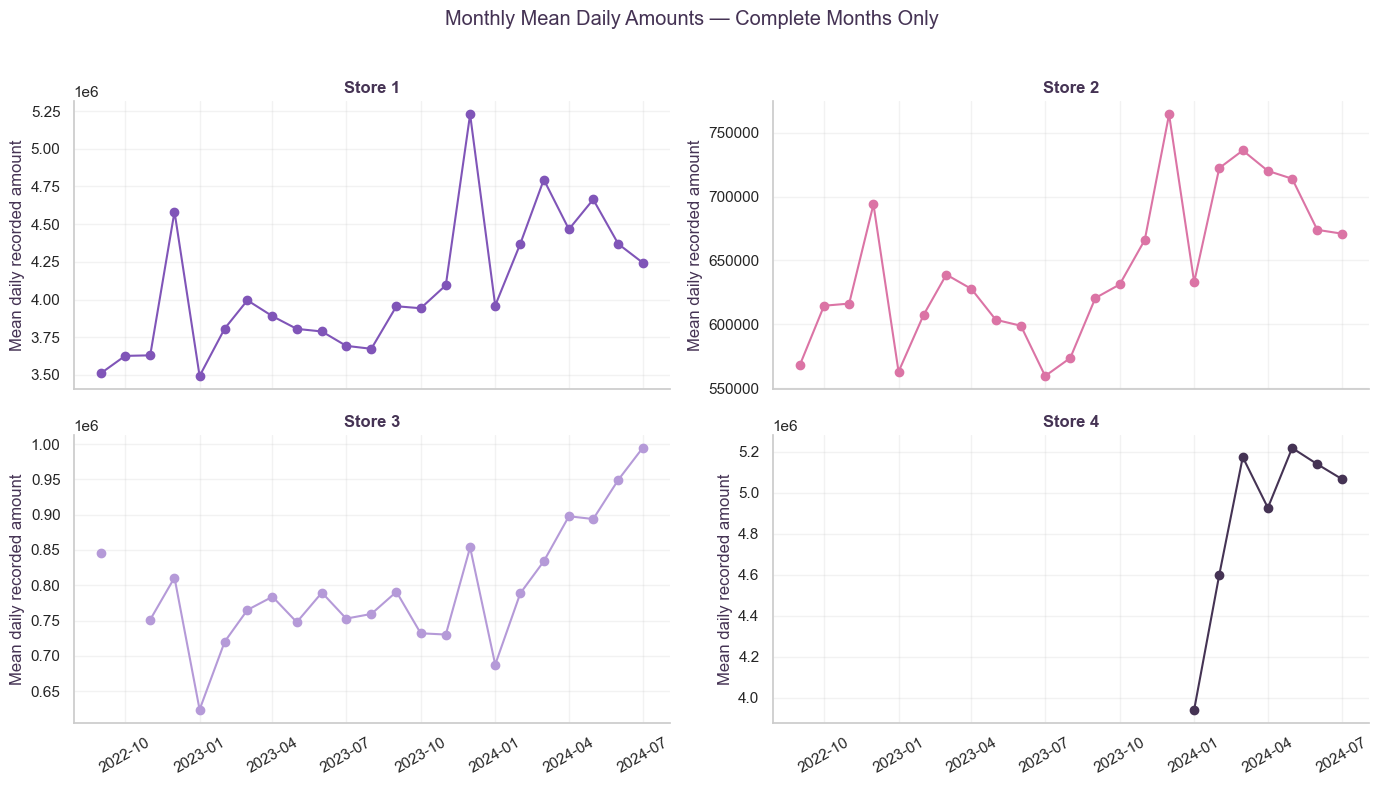

In [37]:
monthly_mean = daily_amount.resample("MS").mean()
monthly_count = daily_amount.resample("MS").count()

expected_days = pd.Series(
    monthly_mean.index.days_in_month,
    index=monthly_mean.index,
)

complete_month = monthly_count.eq(expected_days, axis="index")
monthly_mean_complete = monthly_mean.where(complete_month)

display(monthly_mean_complete.tail(12))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for ax, store_id, color in zip(
    axes.flat, daily_amount.columns, store_colors
):
    ax.plot(
        monthly_mean_complete.index,
        monthly_mean_complete[store_id],
        marker="o",
        color=color,
    )
    ax.set_title(f"Store {store_id}")
    ax.set_ylabel("Mean daily recorded amount")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Monthly Mean Daily Amounts — Complete Months Only")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

,store_id,start,end,days
0,1,2022-08-28,2024-08-29,733
1,2,2022-08-28,2024-08-29,733
2,3,2022-10-17,2024-08-29,683
3,4,2023-12-13,2024-08-29,261


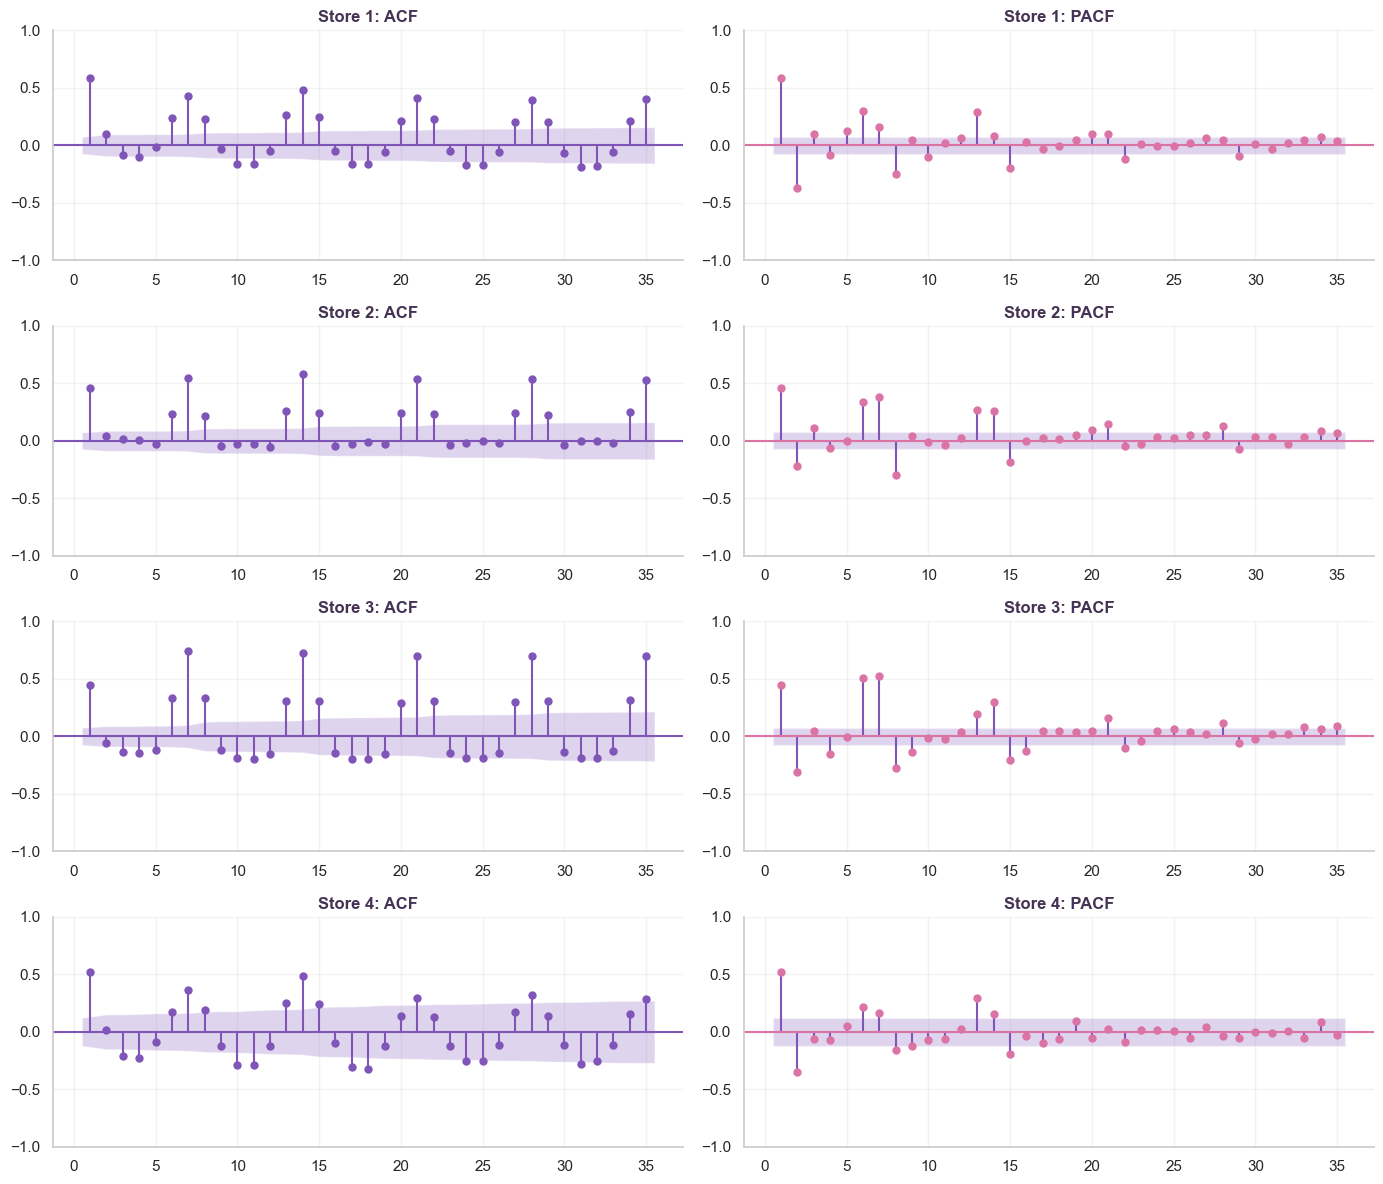

,store_id,series,n,adf_stat,adf_pvalue,adf_lags,kpss_stat,kpss_pvalue,kpss_lags
0,1,original,733,-3.682,0.004381,20,2.701,0.01,2
1,1,first_difference,732,-8.989,6.97e-15,20,0.060,0.1,67
2,1,seasonal_difference_7,726,-8.982,7.255e-15,20,0.009,0.1,10
3,2,original,733,-2.694,0.075,20,3.252,0.01,7
4,2,first_difference,732,-11.489,4.787e-21,19,0.076,0.1,92
5,2,seasonal_difference_7,726,-10.098,1.075e-17,20,0.010,0.1,9
6,3,original,683,-2.292,0.1746,20,2.598,0.01,10
7,3,first_difference,682,-8.707,3.674e-14,20,0.107,0.1,129
8,3,seasonal_difference_7,676,-9.081,4.067e-15,20,0.018,0.1,11
9,4,original,261,-4.737,7.152e-05,16,0.092,0.1,1


KPSS note: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

KPSS note: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.



In [38]:
import warnings

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

diagnostic_series = {}

for store_id in daily_amount.columns:
    series = daily_amount[store_id]
    series = series.loc[series.first_valid_index():].asfreq("D")

    if series.isna().any():
        last_missing = series.index[series.isna()].max()
        series = series.loc[last_missing + pd.Timedelta(days=1):]

    assert series.notna().all()
    diagnostic_series[store_id] = series

diagnostic_coverage = pd.DataFrame([
    {
        "store_id": store_id,
        "start": series.index.min(),
        "end": series.index.max(),
        "days": len(series),
    }
    for store_id, series in diagnostic_series.items()
])

display(diagnostic_coverage)

fig, axes = plt.subplots(
    len(diagnostic_series), 2, figsize=(14, 12)
)

for row, (store_id, series) in enumerate(diagnostic_series.items()):
    plot_acf(
        series,
        lags=35,
        ax=axes[row, 0],
        zero=False,
        color=COLORS["purple"],
    )
    plot_pacf(
        series,
        lags=35,
        ax=axes[row, 1],
        zero=False,
        method="ywm",
        color=COLORS["pink"],
    )

    axes[row, 0].set_title(f"Store {store_id}: ACF")
    axes[row, 1].set_title(f"Store {store_id}: PACF")

plt.tight_layout()
plt.show()

test_rows = []

for store_id, series in diagnostic_series.items():
    transformations = {
        "original": series,
        "first_difference": series.diff().dropna(),
        "seasonal_difference_7": series.diff(7).dropna(),
    }

    for name, values in transformations.items():
        adf_result = adfuller(
            values, regression="c", autolag="AIC"
        )

        # Preserve warnings: KPSS may report a bounded rather than exact p-value.
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            kpss_result = kpss(
                values, regression="c", nlags="auto"
            )

        test_rows.append({
            "store_id": store_id,
            "series": name,
            "n": len(values),
            "adf_stat": adf_result[0],
            "adf_pvalue": adf_result[1],
            "adf_lags": adf_result[2],
            "kpss_stat": kpss_result[0],
            "kpss_pvalue": kpss_result[1],
            "kpss_lags": kpss_result[2],
            "kpss_note": " | ".join(
                str(w.message) for w in caught
            ),
        })

stationarity_tests = pd.DataFrame(test_rows)

display(
    stationarity_tests.drop(columns="kpss_note")
    .style.format({
        "adf_stat": "{:.3f}",
        "adf_pvalue": "{:.4g}",
        "kpss_stat": "{:.3f}",
        "kpss_pvalue": "{:.4g}",
    })
)

for note in stationarity_tests["kpss_note"].unique():
    if note:
        print("KPSS note:", note)

### Stationarity diagnostics

For stores 2 and 3, ADF does not reject a unit root at the 5% level,
while KPSS rejects level stationarity. For store 1, ADF rejects a unit
root but KPSS also rejects level stationarity, giving mixed evidence.

For store 4, ADF rejects a unit root and KPSS does not reject level
stationarity over its shorter observed history. This does not establish
stability outside that period or rule out weekly seasonality.

After first or seven-day differencing, ADF rejects a unit root and KPSS
does not reject level stationarity for all stores. These transformations
are candidates for modelling, rather than mandatory preprocessing.

KPSS p-values at 0.01 and 0.10 may represent table bounds, as indicated
by the warnings. We interpret the tests alongside temporal plots and
will select model specifications using chronological cross-validation.

## 10. Weekly Decomposition and Unusual Days

We compare additive decomposition on the original scale with decomposition
on the logarithmic scale. The latter represents multiplicative behaviour
after exponentiation and requires strictly positive observations.

We use robust STL with a seven-day period. Its trend may also absorb slower
calendar effects; it should not be interpreted as a pure long-term trend.

These decompositions describe the development data retrospectively.
They use observations on both sides of a date and must not be reused
directly as forecasting features.

We inspect the largest residual deviations as candidate unusual days.
They may reflect real events, promotions, partial trading days, or data
issues, so we do not remove them automatically.

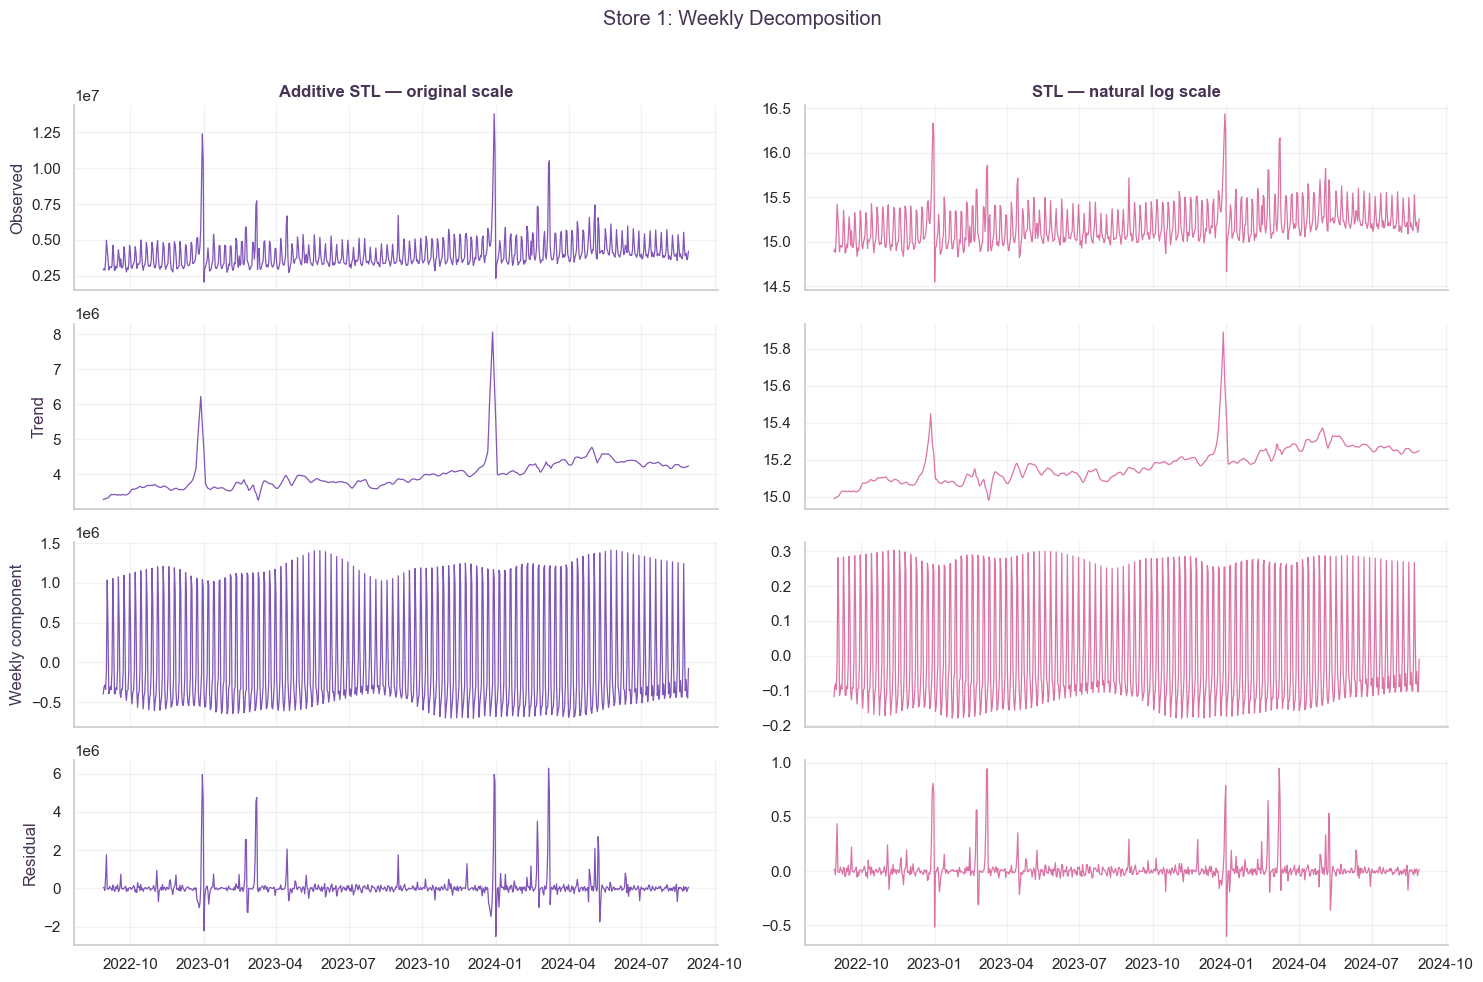

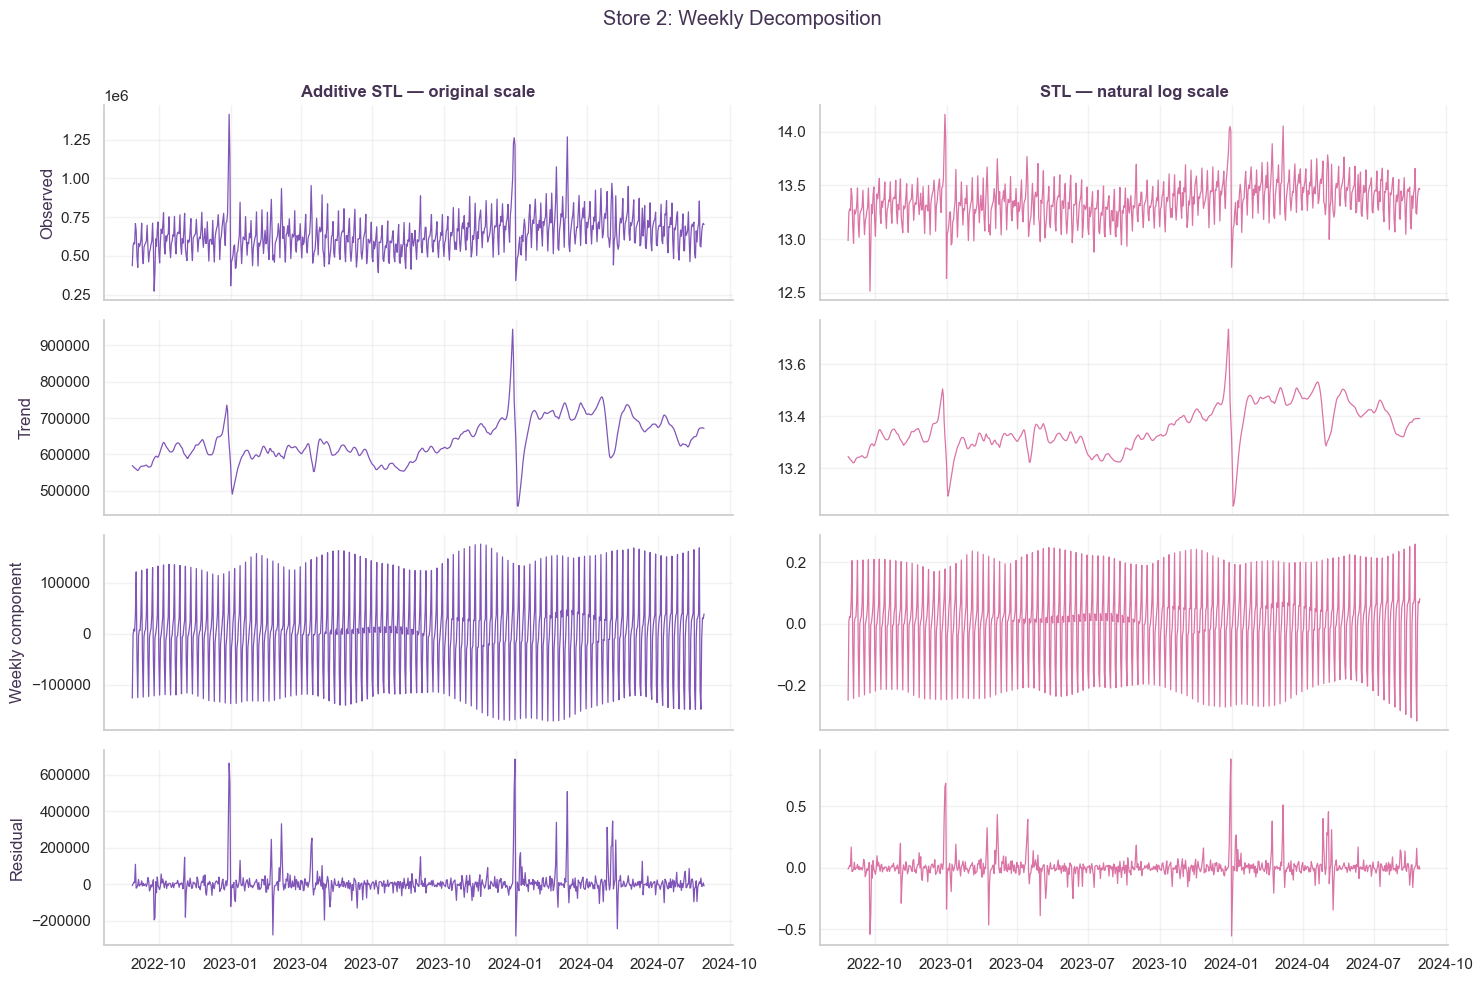

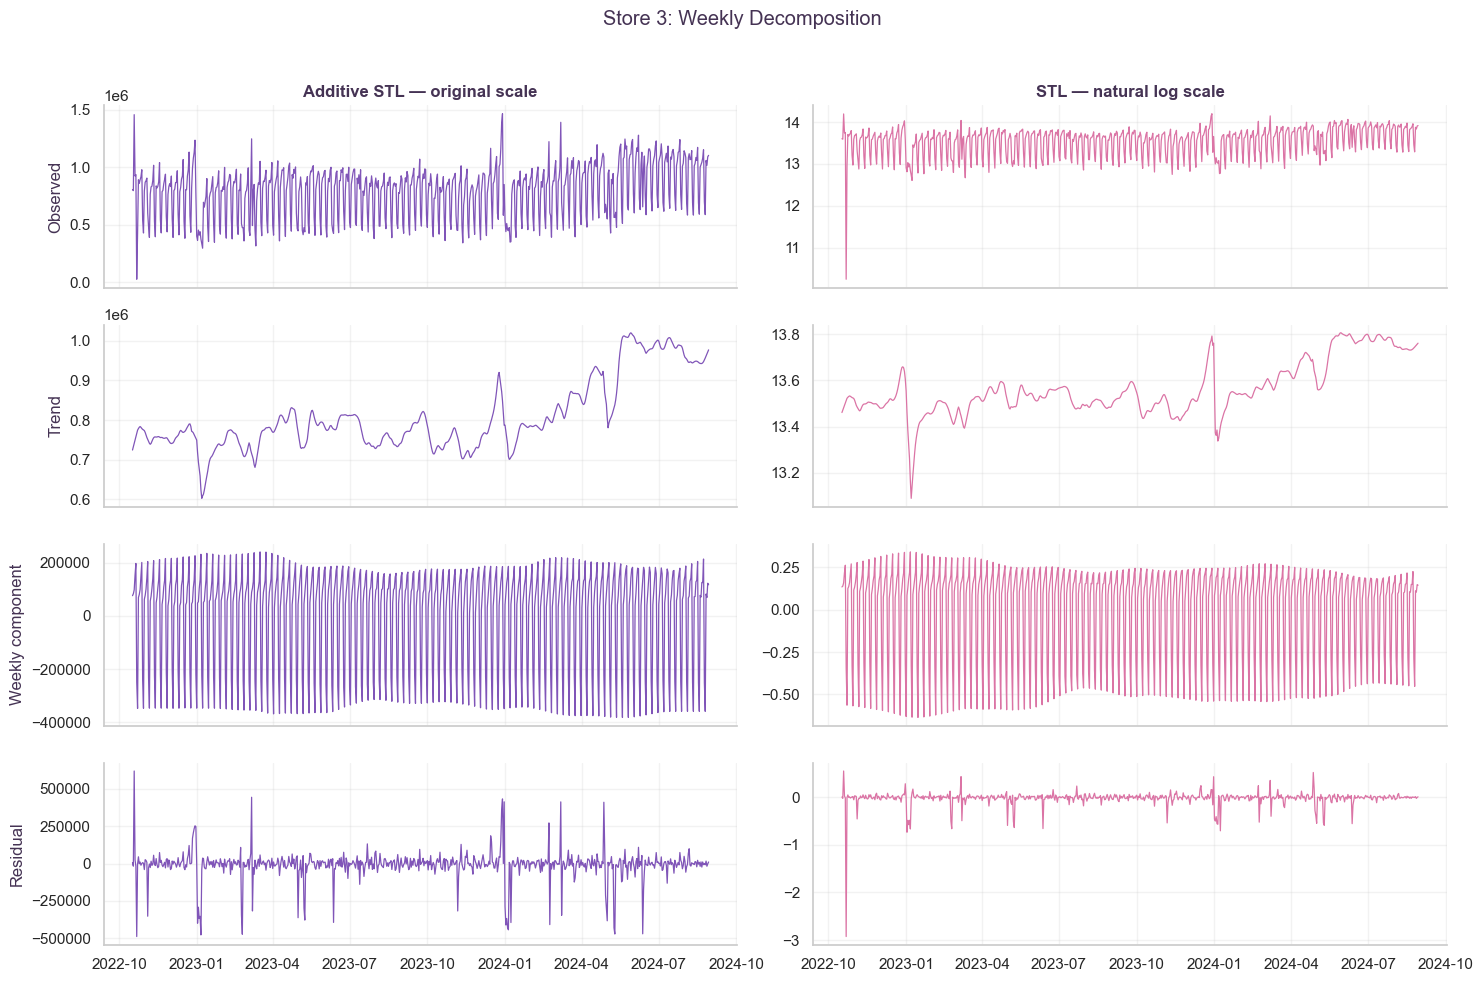

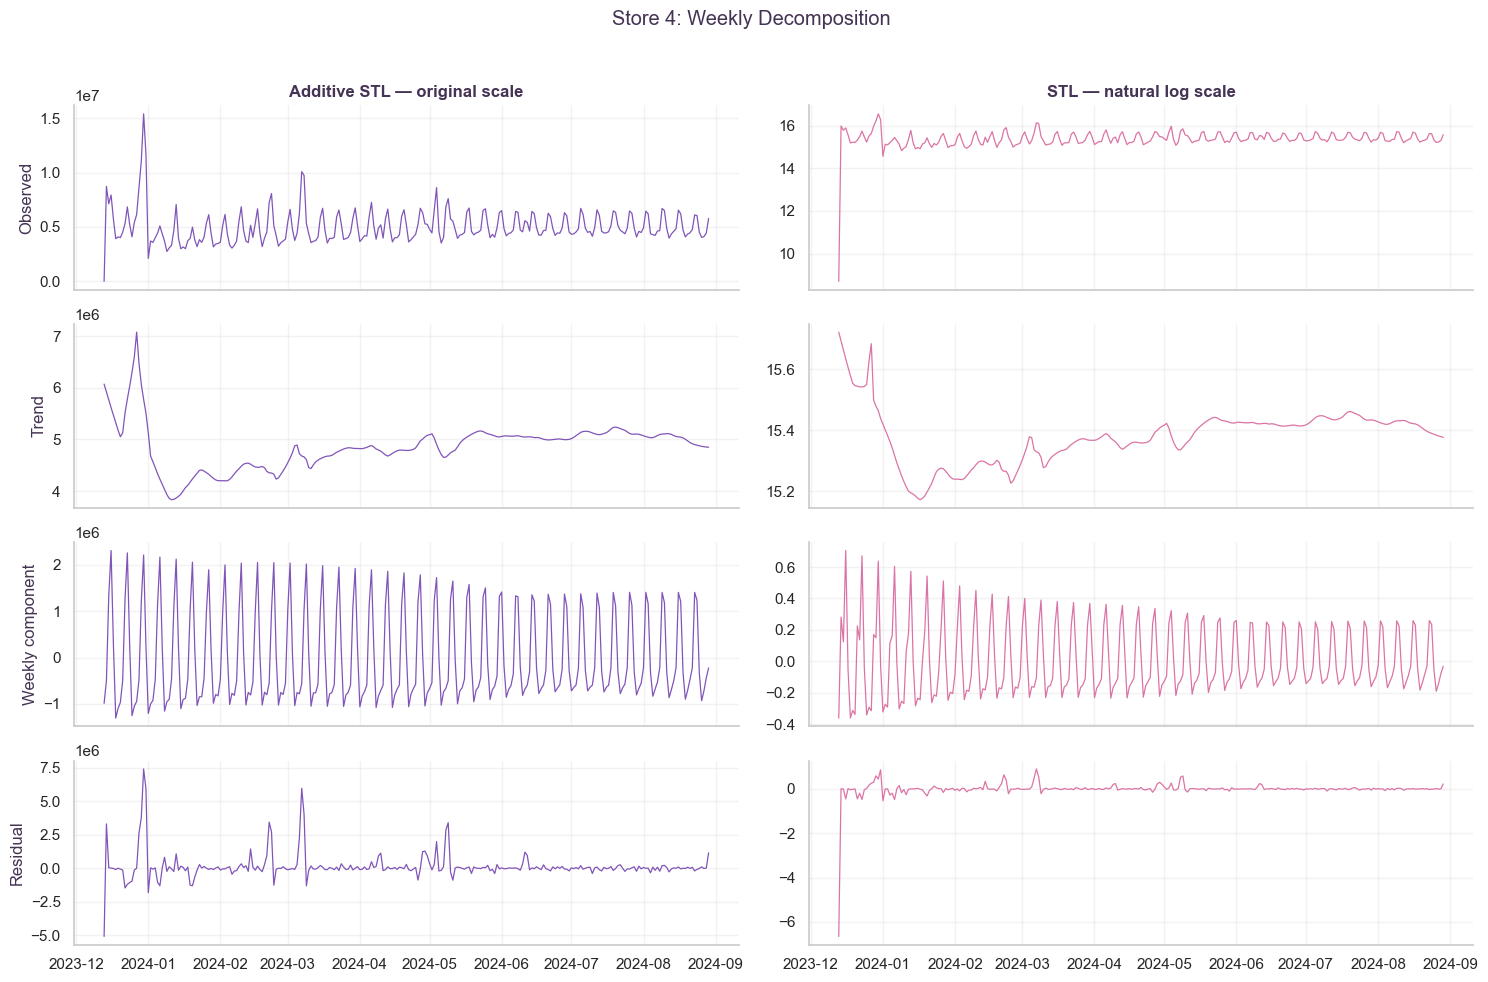

,date,store_id,recorded_amount,retrospective_pattern,ratio_to_pattern,robust_residual_score
0,2024-03-07,1,"10,181,150.930","3,938,199.746",2.585,32.162
1,2023-03-08,1,"7,720,103.280","2,997,405.029",2.576,32.035
2,2023-03-07,1,"7,418,531.480","2,908,081.121",2.551,31.710
3,2022-12-30,1,"12,379,471.250","5,501,076.704",2.250,27.462
4,2023-12-31,1,"11,386,293.460","5,177,487.009",2.199,26.682
5,2023-12-31,2,"1,208,432.080","497,811.029",2.427,26.331
6,2022-12-31,2,"1,135,025.690","569,824.506",1.992,20.455
7,2022-12-30,2,"1,412,803.900","728,465.448",1.939,19.663
8,2023-12-30,2,"1,261,734.590","687,027.243",1.837,18.043
9,2024-01-01,2,"340,450.420","593,520.870",0.574,-16.526


In [39]:
from statsmodels.tsa.seasonal import STL

stl_results = {}
unusual_day_tables = []

for store_id, series in diagnostic_series.items():
    if not series.gt(0).all():
        raise ValueError(
            f"Store {store_id}: log decomposition requires positive amounts."
        )

    additive = STL(
        series, period=7, seasonal=13, robust=True
    ).fit()

    log_result = STL(
        np.log(series), period=7, seasonal=13, robust=True
    ).fit()

    stl_results[store_id] = {
        "additive": additive,
        "log": log_result,
    }

    fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex=True)

    additive_components = [
        series, additive.trend,
        additive.seasonal, additive.resid,
    ]
    log_components = [
        np.log(series), log_result.trend,
        log_result.seasonal, log_result.resid,
    ]
    labels = ["Observed", "Trend", "Weekly component", "Residual"]

    for row, label in enumerate(labels):
        axes[row, 0].plot(
            series.index, additive_components[row],
            color=COLORS["purple"], linewidth=0.9,
        )
        axes[row, 1].plot(
            series.index, log_components[row],
            color=COLORS["pink"], linewidth=0.9,
        )
        axes[row, 0].set_ylabel(label)

    axes[0, 0].set_title("Additive STL — original scale")
    axes[0, 1].set_title("STL — natural log scale")

    fig.suptitle(f"Store {store_id}: Weekly Decomposition")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Rank deviations on the log scale so they reflect relative changes.
    residual = log_result.resid
    residual_median = residual.median()
    mad = (residual - residual_median).abs().median()

    if mad > 0:
        robust_score = (
            (residual - residual_median) / (1.4826 * mad)
        )
    else:
        robust_score = pd.Series(np.nan, index=series.index)

    top_dates = (
        (residual - residual_median)
        .abs()
        .nlargest(5)
        .index
    )

    # Retrospective expected amount excluding the residual.
    fitted_pattern = np.exp(
        log_result.trend + log_result.seasonal
    )

    examples = pd.DataFrame({
        "store_id": store_id,
        "recorded_amount": series.loc[top_dates],
        "retrospective_pattern": fitted_pattern.loc[top_dates],
        "ratio_to_pattern": (
            series.loc[top_dates] / fitted_pattern.loc[top_dates]
        ),
        "robust_residual_score": robust_score.loc[top_dates],
    })

    examples.index.name = "date"
    unusual_day_tables.append(examples.reset_index())

unusual_days = pd.concat(unusual_day_tables, ignore_index=True)
display(unusual_days)

In [40]:
# Aggregate development records once for inspection.
daily_activity = (
    sales_dev
    .assign(
        negative_quantity=lambda d: d["quantity"].lt(0),
        zero_amount=lambda d: d["sum_total"].eq(0),
    )
    .groupby(["date", "store_id"], observed=True)
    .agg(
        item_records=("item_id", "size"),
        negative_quantity_records=("negative_quantity", "sum"),
        zero_amount_records=("zero_amount", "sum"),
    )
    .reset_index()
)

unusual_day_details = unusual_days.merge(
    daily_activity,
    on=["date", "store_id"],
    how="left",
    validate="one_to_one",
)

# Compare recorded item counts with each store's typical observed day.
median_item_records = (
    daily_activity.groupby("store_id")["item_records"].median()
)

unusual_day_details["item_records_vs_store_median"] = (
    unusual_day_details["item_records"]
    / unusual_day_details["store_id"].map(median_item_records)
)

unusual_day_details["weekday"] = (
    unusual_day_details["date"].dt.day_name()
)

display(
    unusual_day_details.sort_values(
        ["store_id", "date"]
    )
)

,date,store_id,recorded_amount,retrospective_pattern,ratio_to_pattern,robust_residual_score,item_records,negative_quantity_records,zero_amount_records,item_records_vs_store_median,weekday
3,2022-12-30,1,"12,379,471.250","5,501,076.704",2.250,27.462,6298,1,1,1.318,Friday
2,2023-03-07,1,"7,418,531.480","2,908,081.121",2.551,31.710,5619,2,4,1.176,Tuesday
1,2023-03-08,1,"7,720,103.280","2,997,405.029",2.576,32.035,5408,0,3,1.132,Wednesday
4,2023-12-31,1,"11,386,293.460","5,177,487.009",2.199,26.682,5858,1,3,1.226,Sunday
0,2024-03-07,1,"10,181,150.930","3,938,199.746",2.585,32.162,6026,2,3,1.261,Thursday
7,2022-12-30,2,"1,412,803.900","728,465.448",1.939,19.663,2132,0,2,1.211,Friday
6,2022-12-31,2,"1,135,025.690","569,824.506",1.992,20.455,1875,1,0,1.065,Saturday
8,2023-12-30,2,"1,261,734.590","687,027.243",1.837,18.043,1977,0,2,1.123,Saturday
5,2023-12-31,2,"1,208,432.080","497,811.029",2.427,26.331,1943,0,2,1.103,Sunday
9,2024-01-01,2,"340,450.420","593,520.870",0.574,-16.526,1134,0,4,0.644,Monday


### Unusual-day findings

Several large positive deviations occur near the end of December and
on March 7–8. Their recurrence suggests calendar-related effects worth
investigating, rather than automatic removal as outliers.

Two low-amount days also have unusually few item records. Store 3 has
112 records on 2022-10-22, approximately 9.8% of its typical daily count.
Store 4 has only 30 records on its first observed date, 2023-12-13.

These observations may reflect partial trading or incomplete recording,
but the available data do not establish the cause. STL estimates at the
series boundary also require caution.

We preserve the original observations. Robust residual scores rank unusual
deviations; they are not calibrated probabilities or automatic deletion rules.

## 11. Category Composition and Item-Series Coverage

We retain unmatched catalog items under an explicit unknown category.
We validate the join and verify that it preserves row counts and amounts.

We describe category composition using positive recorded amounts, keeping
negative amounts separately. Positive amounts are not necessarily gross
revenue because the source data may already contain daily netting.

We measure how concentrated positive amounts are across items. We also
describe item–store record coverage between first and last appearance.
A missing item record is not automatically zero demand or a stockout.

,items,sales_rows,positive_amount,negative_amount,net_amount,positive_amount_share_pct
dept_name,,,,,,
Фрукти,389,119750,"347,298,760.490","-37,624.750","347,261,135.740",6.489
Домашня кухня,5,3047,"345,980,933.630",0.000,"345,980,933.630",6.465
Допоміжна група,83,15001,"203,035,298.470","-214,812.970","202,820,485.500",3.794
Овочі,252,103435,"186,620,326.690","-1,913.310","186,618,413.380",3.487
Тютюнові вироби,315,219484,"167,386,429.990","-2,731.700","167,383,698.290",3.128
Свіже м'ясо,148,35778,"147,211,884.930","-3,609.520","147,208,275.410",2.751
Піца,46,42859,"144,919,074.730","-1,473.140","144,917,601.590",2.708
Вино,1339,134011,"136,860,766.500","-5,677.040","136,855,089.460",2.557
Торти,151,47720,"133,194,068.640","-7,221.460","133,186,847.180",2.489


,items,sales_rows,positive_amount,negative_amount,net_amount,positive_amount_share_pct
dept_name,,,,,,
__UNKNOWN__,616,19068,"31,960,158.880","-3,298.900","31,956,859.980",0.597


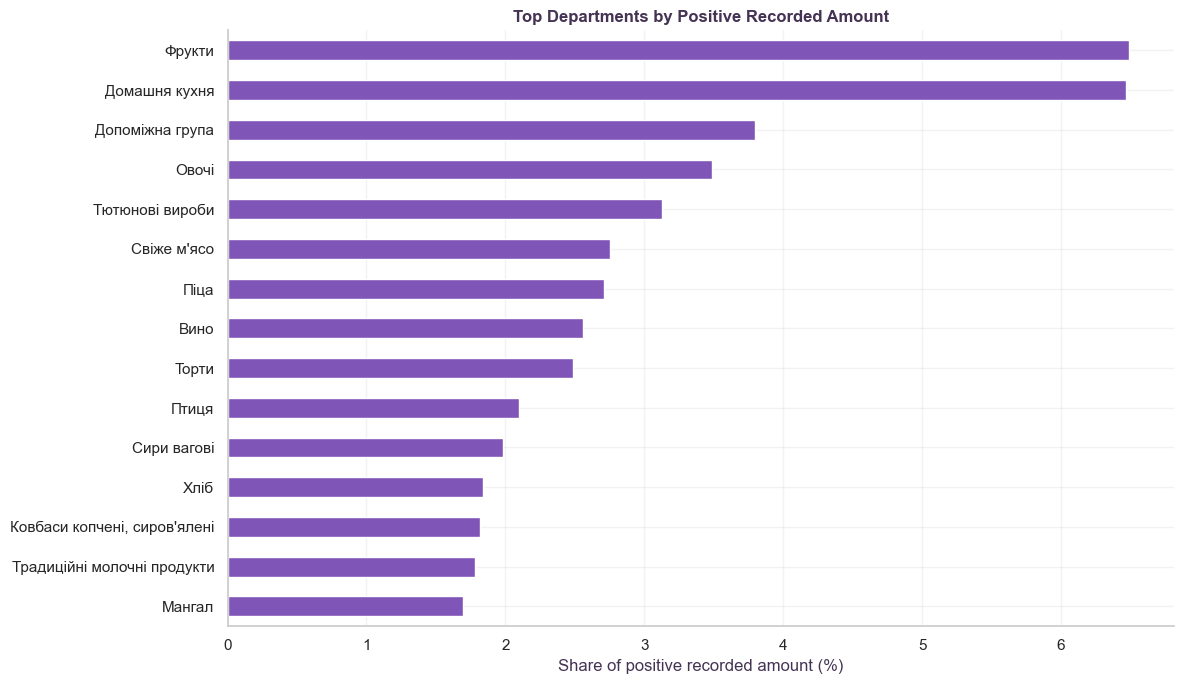

In [41]:
category_columns = ["dept_name", "class_name", "subclass_name"]

assert catalog["item_id"].notna().all()
assert catalog["item_id"].is_unique

# Aggregate before joining to reduce memory use.
item_amounts = (
    sales_dev
    .assign(
        positive_amount=lambda d: d["sum_total"].clip(lower=0),
        negative_amount=lambda d: d["sum_total"].clip(upper=0),
    )
    .groupby("item_id", observed=True)
    .agg(
        sales_rows=("sum_total", "size"),
        net_amount=("sum_total", "sum"),
        positive_amount=("positive_amount", "sum"),
        negative_amount=("negative_amount", "sum"),
    )
    .reset_index()
)

item_categories = item_amounts.merge(
    catalog[["item_id", *category_columns]],
    on="item_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert len(item_categories) == len(item_amounts)
assert np.isclose(
    item_categories["net_amount"].sum(),
    sales_dev["sum_total"].sum(),
)

for column in category_columns:
    item_categories[column] = (
        item_categories[column].fillna("__UNKNOWN__")
    )

category_summary = (
    item_categories
    .groupby("dept_name", observed=True)
    .agg(
        items=("item_id", "size"),
        sales_rows=("sales_rows", "sum"),
        positive_amount=("positive_amount", "sum"),
        negative_amount=("negative_amount", "sum"),
        net_amount=("net_amount", "sum"),
    )
    .sort_values("positive_amount", ascending=False)
)

category_summary["positive_amount_share_pct"] = (
    100 * category_summary["positive_amount"]
    / category_summary["positive_amount"].sum()
)

display(category_summary.head(15))
display(category_summary.loc[
    category_summary.index == "__UNKNOWN__"
])

fig, ax = plt.subplots(figsize=(12, 7))

category_summary.head(15)["positive_amount_share_pct"].sort_values().plot.barh(
    ax=ax,
    color=COLORS["purple"],
)

ax.set_title("Top Departments by Positive Recorded Amount")
ax.set_xlabel("Share of positive recorded amount (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

,positive_amount_share_pct,required_items,share_of_positive_amount_items_pct
0,50.000,564,2.032
1,80.000,3384,12.195
2,90.000,6476,23.337


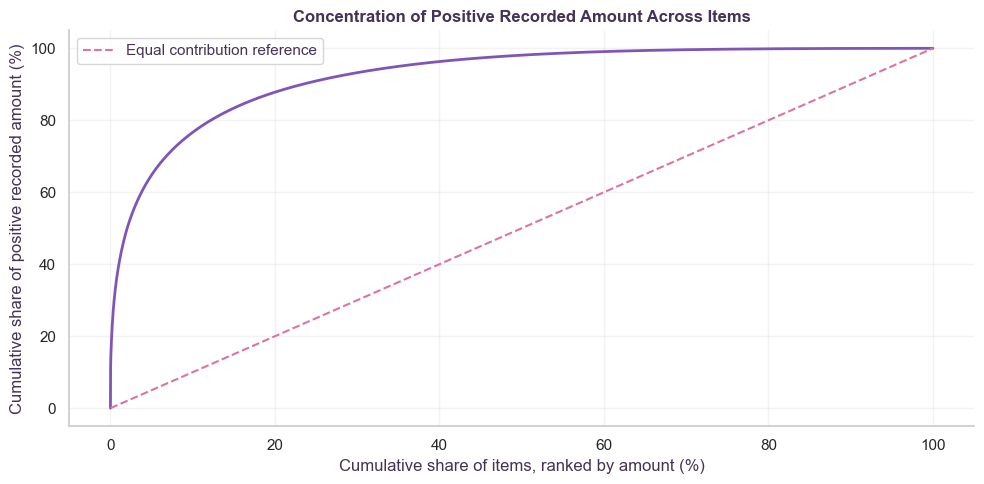

In [42]:
ranked_items = (
    item_amounts.loc[item_amounts["positive_amount"].gt(0)]
    .sort_values("positive_amount", ascending=False)
    .reset_index(drop=True)
)

ranked_items["cumulative_amount_share"] = (
    ranked_items["positive_amount"].cumsum()
    / ranked_items["positive_amount"].sum()
)

ranked_items["cumulative_item_share"] = (
    np.arange(1, len(ranked_items) + 1) / len(ranked_items)
)

concentration_rows = []

for target_share in [0.50, 0.80, 0.90]:
    required_items = int(
        ranked_items["cumulative_amount_share"]
        .searchsorted(target_share)
    ) + 1

    concentration_rows.append({
        "positive_amount_share_pct": 100 * target_share,
        "required_items": required_items,
        "share_of_positive_amount_items_pct": (
            100 * required_items / len(ranked_items)
        ),
    })

display(pd.DataFrame(concentration_rows))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    np.r_[0, ranked_items["cumulative_item_share"]] * 100,
    np.r_[0, ranked_items["cumulative_amount_share"]] * 100,
    color=COLORS["purple"],
    linewidth=2,
)

ax.plot(
    [0, 100], [0, 100],
    linestyle="--", color=COLORS["pink"],
    label="Equal contribution reference",
)

ax.set_title("Concentration of Positive Recorded Amount Across Items")
ax.set_xlabel("Cumulative share of items, ranked by amount (%)")
ax.set_ylabel("Cumulative share of positive recorded amount (%)")
ax.legend()
plt.tight_layout()
plt.show()

### Category composition and concentration findings

Positive recorded amounts are strongly concentrated: 564 items account
for 50% of the total, while 3,384 items account for 80%. These represent
approximately 2.0% and 12.2% of items with positive recorded amounts.

Home-style cooking accounts for 6.465% of positive amounts despite containing
only five observed items. The auxiliary group contributes another 3.794%.
These categories require closer inspection before interpreting their items
as individual physical products.

Items missing from the catalog contribute 0.597% of positive recorded amounts.
We retain them under the unknown category.

In [43]:
departments_to_inspect = ["Домашня кухня", "Допоміжна група"]

special_items = item_categories.loc[
    item_categories["dept_name"].isin(departments_to_inspect)
].copy()

# Display only Ukrainian department labels and numeric measures.
display(
    special_items[
        [
            "item_id", "dept_name", "sales_rows",
            "positive_amount", "negative_amount", "net_amount",
        ]
    ]
    .sort_values("positive_amount", ascending=False)
    .head(20)
)

special_ids = special_items["item_id"]

special_examples = (
    sales_dev.loc[sales_dev["item_id"].isin(special_ids)]
    .nlargest(10, "sum_total")
    .merge(
        special_items[["item_id", "dept_name"]],
        on="item_id",
        how="left",
        validate="many_to_one",
    )
)

display(
    special_examples[
        [
            "date", "store_id", "item_id", "dept_name",
            "quantity", "price_base", "sum_total",
        ]
    ]
)

,item_id,dept_name,sales_rows,positive_amount,negative_amount,net_amount
16914,9a7e315f3f42,Домашня кухня,1895,"310,175,167.820",0.000,"310,175,167.820"
10835,63161948a95a,Допоміжна група,733,"185,688,000.000",0.000,"185,688,000.000"
25147,e7e806fd20a2,Домашня кухня,565,"35,383,732.890",0.000,"35,383,732.890"
19291,b0d24502fb66,Допоміжна група,2164,"14,245,763.050","-2,967.700","14,242,795.350"
15986,92220d068996,Допоміжна група,652,"679,816.740",0.000,"679,816.740"
20399,bba6f7ee0b65,Допоміжна група,2157,"476,715.940",0.000,"476,715.940"
20401,bbac937996b7,Допоміжна група,69,"385,000.000","-37,500.000","347,500.000"
24331,e08d0bf869d2,Домашня кухня,452,"369,034.010",0.000,"369,034.010"
4557,2966b19baa30,Допоміжна група,52,"355,000.000","-30,000.000","325,000.000"
6918,3f64e129e13f,Допоміжна група,137,"263,000.000","-16,000.000","247,000.000"


,date,store_id,item_id,dept_name,quantity,price_base,sum_total
0,2023-12-31,4,9a7e315f3f42,Домашня кухня,"1,158.150",592.780,"686,524.210"
1,2024-03-08,4,9a7e315f3f42,Домашня кухня,"1,148.290",592.300,"680,127.660"
2,2024-03-07,4,9a7e315f3f42,Домашня кухня,"1,075.594",592.050,"636,806.550"
3,2023-12-14,4,9a7e315f3f42,Домашня кухня,"1,056.298",591.380,"624,675.950"
4,2024-05-09,4,9a7e315f3f42,Домашня кухня,982.329,590.030,"579,608.320"
5,2024-05-24,4,9a7e315f3f42,Домашня кухня,943.204,590.910,"557,346.980"
6,2024-04-20,4,9a7e315f3f42,Домашня кухня,962.859,576.640,"555,224.770"
7,2024-08-09,4,9a7e315f3f42,Домашня кухня,851.806,646.900,"551,036.930"
8,2024-01-09,1,63161948a95a,Допоміжна група,"1,219.000",450.000,"548,550.000"
9,2024-02-23,4,9a7e315f3f42,Домашня кухня,917.770,592.340,"543,633.890"


## 12. Online Sales and Channel Overlap

We inspect online records within the development period and compare them
with sales records using date, store, and item identifiers.

We distinguish shared keys from matching quantities and amounts.
Neither shared keys nor matching values alone establish whether online
sales are included in the sales table.

Until the channel definitions are verified, we keep the tables separate
and do not add their amounts together.

In [44]:
online_dev = pd.read_csv(
    DATA_DIR / "online.csv",
    usecols=SALES_COLUMNS,
    dtype={
        "date": "string",
        "item_id": "string",
        "store_id": "Int64",
        "quantity": "float64",
        "price_base": "float64",
        "sum_total": "float64",
    },
)

online_dev["date"] = pd.to_datetime(
    online_dev["date"],
    format="%Y-%m-%d",
    errors="raise",
)

online_dev = online_dev.loc[
    online_dev["date"] < TEST_START
].copy()

key = ["date", "store_id", "item_id"]

online_checks = pd.Series({
    "development_rows": len(online_dev),
    "missing_key_rows": int(
        online_dev[key].isna().any(axis=1).sum()
    ),
    "duplicate_key_rows_beyond_first": int(
        online_dev.duplicated(key).sum()
    ),
    "negative_amount_rows": int(online_dev["sum_total"].lt(0).sum()),
}, name="count")

display(online_checks.to_frame())

display(
    online_dev.groupby("store_id").agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observed_days=("date", "nunique"),
        rows=("item_id", "size"),
    )
)

,count
development_rows,1072189
missing_key_rows,0
duplicate_key_rows_beyond_first,0
negative_amount_rows,5


,first_date,last_date,observed_days,rows
store_id,,,,
1,2022-08-28,2024-08-29,733,848555
4,2023-12-13,2024-08-29,261,223634


,value
online_keys,"1,072,189.000"
keys_also_in_sales,"864,736.000"
shared_keys_pct,80.651
quantity_and_amount_match_among_shared_keys_pct,0.001


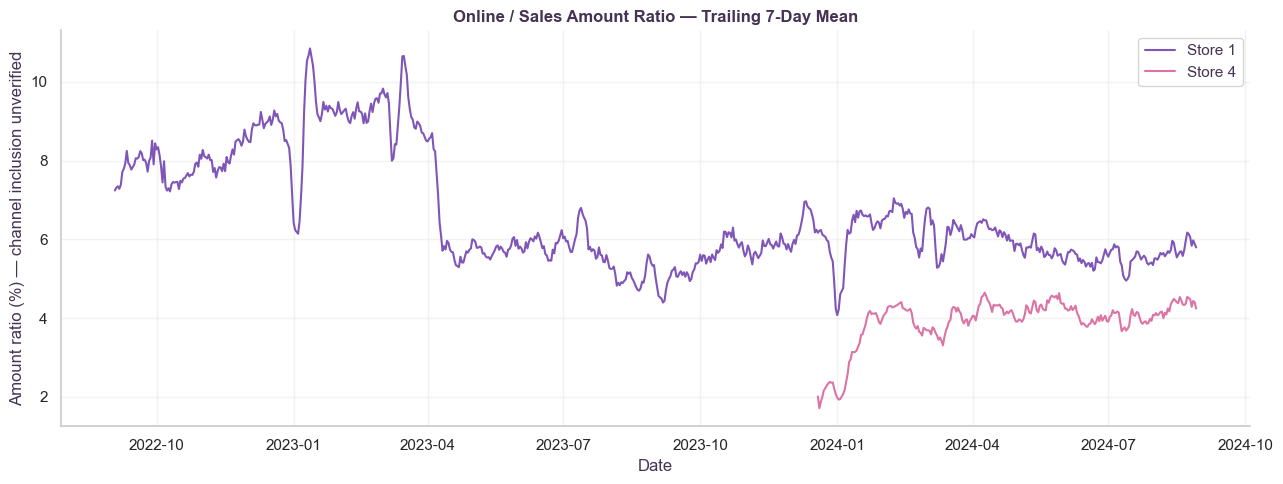

In [45]:
# Aggregate online keys explicitly if they contain multiple records.
online_by_key = (
    online_dev
    .groupby(key, observed=True, dropna=False)[
        ["quantity", "sum_total"]
    ]
    .sum(min_count=1)
    .reset_index()
)

channel_comparison = online_by_key.merge(
    sales_dev[key + ["quantity", "sum_total"]],
    on=key,
    how="left",
    suffixes=("_online", "_sales"),
    indicator=True,
    validate="one_to_one",
)

matched = channel_comparison["_merge"].eq("both")

quantity_matches = pd.Series(
    np.isclose(
        channel_comparison["quantity_online"],
        channel_comparison["quantity_sales"],
        atol=1e-6,
        rtol=1e-6,
        equal_nan=False,
    ),
    index=channel_comparison.index,
)

amount_matches = pd.Series(
    np.isclose(
        channel_comparison["sum_total_online"],
        channel_comparison["sum_total_sales"],
        atol=0.01,
        rtol=0,
        equal_nan=False,
    ),
    index=channel_comparison.index,
)

overlap_summary = pd.Series({
    "online_keys": len(channel_comparison),
    "keys_also_in_sales": int(matched.sum()),
    "shared_keys_pct": 100 * matched.mean(),
    "quantity_and_amount_match_among_shared_keys_pct": (
        100 * (quantity_matches & amount_matches)[matched].mean()
    ),
}, name="value")

display(overlap_summary.to_frame())

# Ratios describe relative amounts; they are not verified channel shares.
online_daily_amount = (
    online_dev
    .groupby(["date", "store_id"], observed=True)["sum_total"]
    .sum(min_count=1)
    .unstack("store_id")
    .reindex(daily_amount.index)
)

fig, ax = plt.subplots(figsize=(13, 5))

for store_id in online_daily_amount.columns:
    ratio = (
        online_daily_amount[store_id]
        / daily_amount[store_id].where(daily_amount[store_id].gt(0))
        * 100
    )

    ax.plot(
        ratio.index,
        ratio.rolling(7, min_periods=7).mean(),
        label=f"Store {store_id}",
    )

ax.set_title("Online / Sales Amount Ratio — Trailing 7-Day Mean")
ax.set_ylabel("Amount ratio (%) — channel inclusion unverified")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.show()

### Online channel and special-item findings

Online development records have unique date–store–item keys and cover
stores 1 and 4. Approximately 80.651% of online keys also appear in sales,
but quantities and amounts match in only approximately 0.001% of shared keys.

This comparison does not establish channel inclusion. We keep the sources
separate to avoid double counting.

Two items dominate the inspected special categories: one home-style cooking
item contributes approximately 310.2 million in positive recorded amounts,
and one auxiliary item contributes approximately 185.7 million.
Their identities require clarification before item-level demand modelling.
We retain them in the original recorded-amount totals.

## 13. Prices, Promotions, Markdowns, and Assortment Records

We inspect auxiliary records dated before the final holdout. We check
missing keys, repeated keys, price ranges, and promotion-price consistency.

A record's effective date does not establish when it became available.
Future prices and promotions require evidence that they were known at
the forecast origin before they can be used as predictors.

We inspect the structure of actual_matrix without assuming that its dates
describe daily availability, stock levels, or assortment entry.

In [46]:
def load_auxiliary_development(filename):
    parts = []
    invalid_dates = 0
    excluded_rows = 0

    for chunk in pd.read_csv(
        DATA_DIR / filename,
        usecols=lambda column: column != "Unnamed: 0",
        dtype={"item_id": "string", "store_id": "Int64"},
        chunksize=200_000,
    ):
        parsed = pd.to_datetime(
            chunk["date"], format="%Y-%m-%d", errors="coerce"
        )

        invalid_dates += int(parsed.isna().sum())
        excluded_rows += int(parsed.ge(TEST_START).sum())

        chunk["date"] = parsed
        parts.append(chunk.loc[parsed.lt(TEST_START)].copy())

    if invalid_dates:
        raise ValueError(
            f"{filename}: {invalid_dates:,} missing or invalid dates."
        )

    result = pd.concat(parts, ignore_index=True)

    print(
        f"{filename}: {len(result):,} development records; "
        f"{excluded_rows:,} records dated on/after holdout start excluded."
    )
    return result


price_dev = load_auxiliary_development("price_history.csv")
promo_dev = load_auxiliary_development("discounts_history.csv")
markdown_dev = load_auxiliary_development("markdowns.csv")
matrix_dev = load_auxiliary_development("actual_matrix.csv")

aux_tables = {
    "prices": price_dev,
    "promotions": promo_dev,
    "markdowns": markdown_dev,
    "assortment_matrix": matrix_dev,
}

aux_summary = []

for name, table in aux_tables.items():
    aux_summary.append({
        "table": name,
        "rows": len(table),
        "first_date": table["date"].min(),
        "last_date": table["date"].max(),
        "items": table["item_id"].nunique(),
        "stores": table["store_id"].nunique(),
        "missing_key_rows": int(table[key].isna().any(axis=1).sum()),
        "repeated_key_rows_beyond_first": int(
            table.duplicated(key).sum()
        ),
        "exact_duplicate_rows_beyond_first": int(
            table.duplicated().sum()
        ),
    })

display(pd.DataFrame(aux_summary).set_index("table"))

price_history.csv: 669,109 development records; 29,517 records dated on/after holdout start excluded.
discounts_history.csv: 3,260,759 development records; 485,985 records dated on/after holdout start excluded.
markdowns.csv: 8,623 development records; 356 records dated on/after holdout start excluded.
actual_matrix.csv: 33,819 development records; 1,383 records dated on/after holdout start excluded.


,rows,first_date,last_date,items,stores,missing_key_rows,repeated_key_rows_beyond_first,exact_duplicate_rows_beyond_first
table,,,,,,,,
prices,669109,2022-08-28,2024-08-29,36861,4,0,79735,18626
promotions,3260759,2022-08-28,2024-08-29,15774,4,0,0,0
markdowns,8623,2022-08-28,2024-08-29,311,3,0,268,268
assortment_matrix,33819,2019-10-17,2024-08-29,14748,4,0,0,0


,table,column,missing,infinite,negative,zero,median,p99,maximum
0,prices,price,0,0,0,59083,149.900,"2,399.900","118,496,741.220"
1,promotions,sale_price_before_promo,0,0,0,20135,189.900,"2,999.900","16,999.900"
2,promotions,sale_price_time_promo,0,0,0,29,149.900,"2,490.000","15,999.900"
3,markdowns,normal_price,0,0,0,2,239.000,879.000,"2,790.000"
4,markdowns,price,0,0,0,0,150.000,620.000,"1,380.500"


,count
promo_price_above_original_rows,38063
nonpositive_original_price_rows,20135
nonpositive_duration_rows,0
missing_duration_rows,0
duration_above_366_days_rows,47768
valid_discount_price_pairs,3222668


,discount_pct
count,"3,222,668.000"
mean,19.478
std,13.342
min,0.000
10%,0.000
50%,20.001
90%,36.430
99%,50.638
max,100.000


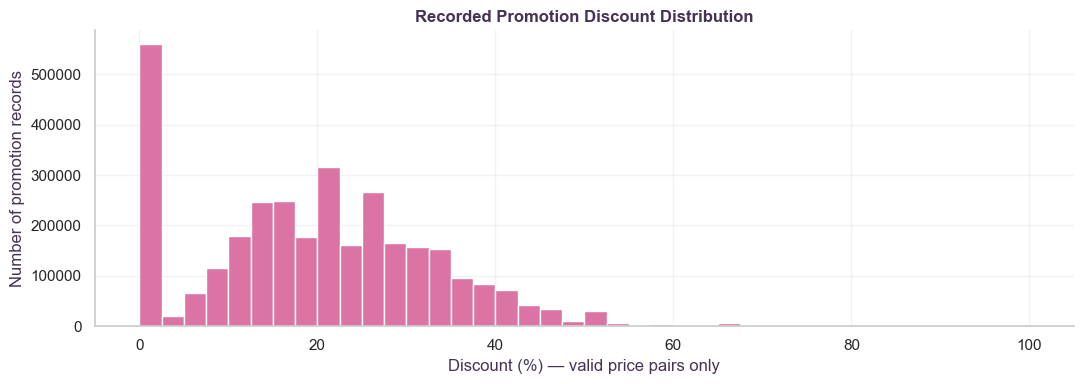

,date,store_id,item_id,price,code
200687,2022-12-02,1,110213902296,"118,496,741.220",1
200685,2022-12-02,1,5b77d3454710,"118,496,731.860",1
414227,2022-09-23,2,75fe6dc46c61,"15,690,156.400",3
188885,2022-11-11,1,2848ba16f5ad,"159,990.000",1
453794,2023-04-03,2,2848ba16f5ad,"99,999.900",1
558855,2023-04-03,3,2848ba16f5ad,"99,999.900",1
29468,2023-10-08,1,2848ba16f5ad,"89,999.900",1
329261,2023-10-08,2,2848ba16f5ad,"89,999.900",1
493240,2023-10-08,3,2848ba16f5ad,"89,999.900",1
188663,2022-11-11,1,3a703f29cc76,"59,990.000",1


In [47]:
price_fields = {
    "prices": ["price"],
    "promotions": ["sale_price_before_promo", "sale_price_time_promo"],
    "markdowns": ["normal_price", "price"],
}

price_checks = []

for name, columns in price_fields.items():
    table = aux_tables[name]

    for column in columns:
        values = table[column]

        price_checks.append({
            "table": name,
            "column": column,
            "missing": int(values.isna().sum()),
            "infinite": int(np.isinf(values).sum()),
            "negative": int(values.lt(0).sum()),
            "zero": int(values.eq(0).sum()),
            "median": values.median(),
            "p99": values.quantile(0.99),
            "maximum": values.max(),
        })

display(pd.DataFrame(price_checks))

promo_before = promo_dev["sale_price_before_promo"]
promo_during = promo_dev["sale_price_time_promo"]

promo_valid = (
    np.isfinite(promo_before)
    & np.isfinite(promo_during)
    & promo_before.gt(0)
    & promo_during.ge(0)
    & promo_during.le(promo_before)
)

promo_checks = pd.Series({
    "promo_price_above_original_rows": int(
        promo_during.gt(promo_before).sum()
    ),
    "nonpositive_original_price_rows": int(promo_before.le(0).sum()),
    "nonpositive_duration_rows": int(
        promo_dev["number_disc_day"].le(0).sum()
    ),
    "missing_duration_rows": int(
        promo_dev["number_disc_day"].isna().sum()
    ),
    "duration_above_366_days_rows": int(
        promo_dev["number_disc_day"].gt(366).sum()
    ),
    "valid_discount_price_pairs": int(promo_valid.sum()),
}, name="count")

display(promo_checks.to_frame())

discount_pct = (
    100 * (1 - promo_during.loc[promo_valid]
           / promo_before.loc[promo_valid])
)

display(
    discount_pct.describe(
        percentiles=[0.1, 0.5, 0.9, 0.99]
    ).rename("discount_pct").to_frame()
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.hist(
    discount_pct,
    bins=40,
    color=COLORS["pink"],
    edgecolor="white",
)

ax.set_title("Recorded Promotion Discount Distribution")
ax.set_xlabel("Discount (%) — valid price pairs only")
ax.set_ylabel("Number of promotion records")
plt.tight_layout()
plt.show()

# Inspect extremes without automatically removing them.
display(
    price_dev.nlargest(10, "price")[
        ["date", "store_id", "item_id", "price", "code"]
    ]
)

In [48]:
matrix_pair_structure = (
    matrix_dev
    .groupby(["store_id", "item_id"], observed=True)
    .agg(
        records=("date", "size"),
        unique_dates=("date", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
    )
    .reset_index()
)

display(
    matrix_pair_structure[
        ["records", "unique_dates"]
    ].describe(percentiles=[0.5, 0.9, 0.99])
)

matrix_pair_keys = pd.MultiIndex.from_frame(
    matrix_dev[["store_id", "item_id"]].drop_duplicates()
)
sales_pair_keys = pd.MultiIndex.from_frame(
    sales_dev[["store_id", "item_id"]].drop_duplicates()
)

matrix_comparison = pd.Series({
    "development_sales_pairs": len(sales_pair_keys),
    "matrix_pairs_before_holdout": len(matrix_pair_keys),
    "sales_pairs_present_in_matrix": len(
        sales_pair_keys.intersection(matrix_pair_keys)
    ),
    "sales_pairs_absent_from_matrix": len(
        sales_pair_keys.difference(matrix_pair_keys)
    ),
    "matrix_pairs_with_one_unique_date_pct": (
        100 * matrix_pair_structure["unique_dates"].eq(1).mean()
    ),
}, name="value")

display(matrix_comparison.to_frame())

,records,unique_dates
count,"33,819.000","33,819.000"
mean,1.000,1.000
std,0.000,0.000
min,1.000,1.000
50%,1.000,1.000
90%,1.000,1.000
99%,1.000,1.000
max,1.000,1.000


,value
development_sales_pairs,"57,069.000"
matrix_pairs_before_holdout,"33,819.000"
sales_pairs_present_in_matrix,"30,689.000"
sales_pairs_absent_from_matrix,"26,380.000"
matrix_pairs_with_one_unique_date_pct,100.000


### Auxiliary data findings

Price history contains 79,735 repeated date–store–item keys, including
18,626 exact duplicate rows. It also contains zero prices and extreme
values, with a maximum of approximately 118.5 million. A direct join
would risk multiplying sales records.

Promotion records have unique keys, but 38,063 records have a promotion
price above the original price, and 47,768 have durations above 366 days.
The median discount among valid price pairs is approximately 20%.
These statistics describe recorded promotions, not their causal effects.

Markdown records contain 268 exact duplicate rows. Without transaction
identifiers, identical records cannot automatically be classified as errors.

Every assortment item–store pair has exactly one recorded date.
Furthermore, 26,380 development sales pairs are absent from this table.
We therefore do not treat it as a daily availability history or use it
to infer zero demand.

For the initial forecasting comparison, we use historical sales and calendar
features. Auxiliary prices and promotions require separate resolution of
their semantics, conflicting records, and availability at each forecast origin.

,observed_days,span_days,record_coverage_pct
count,"57,069.000","57,069.000","57,069.000"
mean,123.556,332.932,39.162
std,159.938,252.540,31.081
min,1.000,1.000,0.295
10%,4.000,27.000,4.678
25%,14.000,121.000,11.686
50%,55.000,259.000,30.769
75%,172.000,595.000,62.992
90%,349.000,729.000,90.580
max,733.000,733.000,100.000


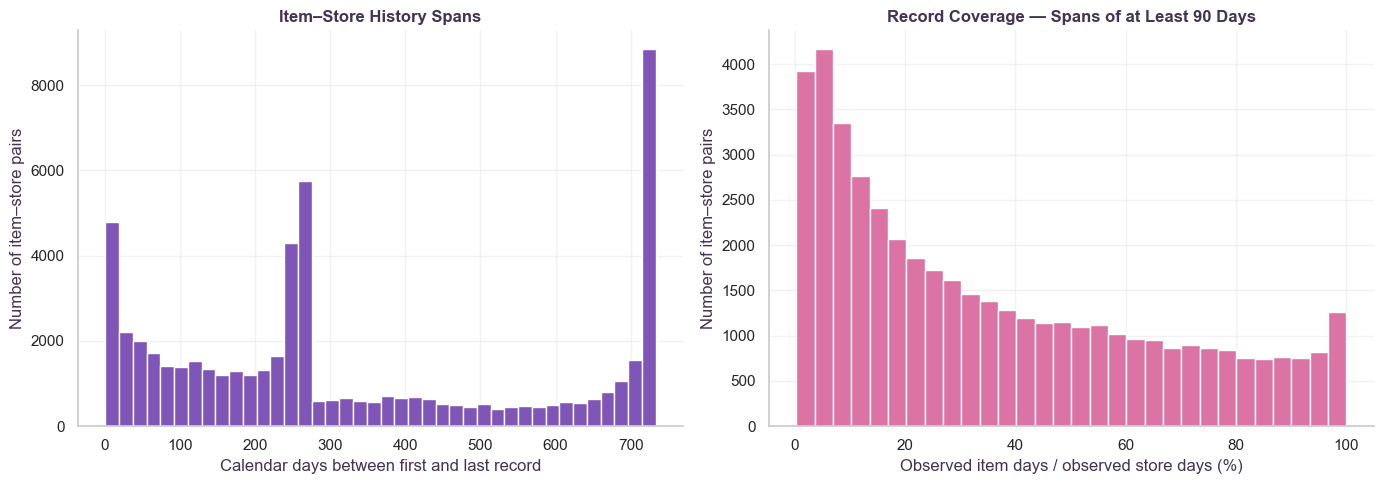

In [49]:
item_store_coverage = (
    sales_dev
    .groupby(["store_id", "item_id"], observed=True)
    .agg(
        first_record=("date", "min"),
        last_record=("date", "max"),
        observed_days=("date", "nunique"),
    )
    .reset_index()
)

item_store_coverage["span_days"] = (
    item_store_coverage["last_record"]
    - item_store_coverage["first_record"]
).dt.days + 1

item_store_coverage["store_observed_days_in_span"] = 0

for store_id in daily_amount.columns:
    dates = daily_amount.index[
        daily_amount[store_id].notna()
    ].to_numpy(dtype="datetime64[ns]")

    mask = item_store_coverage["store_id"].eq(store_id)

    starts = item_store_coverage.loc[
        mask, "first_record"
    ].to_numpy(dtype="datetime64[ns]")

    ends = item_store_coverage.loc[
        mask, "last_record"
    ].to_numpy(dtype="datetime64[ns]")

    item_store_coverage.loc[
        mask, "store_observed_days_in_span"
    ] = (
        np.searchsorted(dates, ends, side="right")
        - np.searchsorted(dates, starts, side="left")
    )

item_store_coverage["record_coverage_pct"] = (
    100 * item_store_coverage["observed_days"]
    / item_store_coverage["store_observed_days_in_span"]
)

display(
    item_store_coverage[
        ["observed_days", "span_days", "record_coverage_pct"]
    ].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    item_store_coverage["span_days"],
    bins=40, color=COLORS["purple"], edgecolor="white",
)
axes[0].set_title("Item–Store History Spans")
axes[0].set_xlabel("Calendar days between first and last record")
axes[0].set_ylabel("Number of item–store pairs")

long_history = item_store_coverage["span_days"].ge(90)

axes[1].hist(
    item_store_coverage.loc[long_history, "record_coverage_pct"],
    bins=30, color=COLORS["pink"], edgecolor="white",
)
axes[1].set_title("Record Coverage — Spans of at Least 90 Days")
axes[1].set_xlabel("Observed item days / observed store days (%)")
axes[1].set_ylabel("Number of item–store pairs")

plt.tight_layout()
plt.show()

In [50]:
cv_rows = []

for fold in range(1, 5):
    validation_start = (
        TEST_START - pd.Timedelta(days=28 * (5 - fold))
    )
    validation_end = validation_start + pd.Timedelta(days=27)

    cv_rows.append({
        "fold": fold,
        "train_end": validation_start - pd.Timedelta(days=1),
        "validation_start": validation_start,
        "validation_end": validation_end,
        "horizon_days": FORECAST_HORIZON,
    })

cv_schedule = pd.DataFrame(cv_rows)

assert cv_schedule["validation_end"].max() < TEST_START
display(cv_schedule)

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


## 14. Conclusions and Forecasting Design

### Item-level coverage

We identified 57,069 item–store pairs. The median pair has records on
55 days, and the median record coverage within its observed history is
30.769%. Even long histories often contain many dates without item records.

These gaps do not establish zero demand. We lack a verified daily
availability history, so filling every absent item record with zero
would introduce an unsupported assumption.

### Forecasting task

We forecast the daily recorded amount, obtained by summing sum_total
within each store, for the next 28 days. We model four stores separately
or use a global model with store-specific features.

The target describes monetary sales as recorded in sales.csv, including
adjustments. It is not a measure of unconstrained physical demand.
Online amounts are not added because channel inclusion remains unresolved.

### Data handling

We preserve recorded amounts and do not automatically remove unusual days.
The missing store-day remains missing. Dates before a store's first
appearance are outside its observed history.

Any imputation, scaling, transformation, or outlier treatment used for
forecasting must be fitted within the corresponding training fold.
Retrospective STL components are not exported as forecasting features.

### Evaluation

We use four expanding-window cross-validation folds with 28-day
validation horizons, covering 2024-05-10 through 2024-08-29.

The final holdout is 2024-08-30 through 2024-09-26. It remains excluded
from model selection. We report errors for each store and summarize
performance across stores and folds.

These validation windows cover late spring and summer only, so they
provide limited evidence about performance around year-end peaks.

### Modelling implications

Store-specific weekday patterns motivate weekly seasonal baselines,
seasonal statistical models, and store–weekday interactions.

Calendar-related peaks motivate calendar features, subject to verified
event relevance. Auxiliary prices and promotions require further
semantic and availability checks before predictive use.

All model training and comparison are performed in separate notebooks.

In [51]:
import json

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Export each store from its first observed date.
# Keep internal missing dates, including store 3's missing day.
daily_export_parts = []

for store_id in daily_amount.columns:
    series = daily_amount[store_id]
    series = series.loc[series.first_valid_index():]

    part = series.rename("y").reset_index()
    part.columns = ["date", "y"]
    part["store_id"] = int(store_id)
    part["is_observed"] = part["y"].notna()

    daily_export_parts.append(
        part[["date", "store_id", "y", "is_observed"]]
    )

daily_export = (
    pd.concat(daily_export_parts, ignore_index=True)
    .sort_values(["store_id", "date"])
    .reset_index(drop=True)
)

assert not daily_export.duplicated(["date", "store_id"]).any()
assert daily_export["date"].max() < TEST_START
assert np.isclose(
    daily_export["y"].sum(),
    sales_dev["sum_total"].sum(),
)

daily_export.to_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    index=False,
    date_format="%Y-%m-%d",
    encoding="utf-8",
)

cv_schedule.to_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    index=False,
    date_format="%Y-%m-%d",
)

item_store_coverage.to_csv(
    PROCESSED_DIR / "retail_item_store_coverage.csv",
    index=False,
    date_format="%Y-%m-%d",
)

config = {
    "source": "sales.csv",
    "target": "sum_total",
    "aggregation": "daily sum by store",
    "frequency": "D",
    "forecast_horizon_days": int(FORECAST_HORIZON),
    "development_end": (
        TEST_START - pd.Timedelta(days=1)
    ).strftime("%Y-%m-%d"),
    "test_start": TEST_START.strftime("%Y-%m-%d"),
    "test_end": TEST_END.strftime("%Y-%m-%d"),
    "store_ids": [int(s) for s in daily_amount.columns],
    "cv_folds": len(cv_schedule),
    "cv_strategy": "expanding window",
    "missing_day_policy": "preserve; fit imputation within training folds",
    "outlier_policy": "retain original observations",
    "online_added": False,
    "retrospective_stl_features_exported": False,
}

with (PROCESSED_DIR / "retail_forecasting_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(config, file, ensure_ascii=False, indent=2)

# Verify the main exported file can be read correctly.
reloaded = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

assert len(reloaded) == len(daily_export)
assert reloaded["y"].isna().sum() == daily_export["y"].isna().sum()
assert np.isclose(reloaded["y"].sum(), daily_export["y"].sum())

print("Saved development data, coverage, CV schedule, and configuration.")
display(daily_export.groupby("store_id").agg(
    calendar_days=("date", "size"),
    observed_days=("is_observed", "sum"),
))

Saved development data, coverage, CV schedule, and configuration.


,calendar_days,observed_days
store_id,,
1,733,733
2,733,733
3,733,732
4,261,261
